# **Access Drive File**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Cross-Dimensional Transformer with Adaptive Fusion for Graph-Free EEG-Based**
# **Emotion Recognition**

# **Dataset link**

# **https://www.kaggle.com/datasets/harshilgupta28/deap-dataset**

# **dat to csv conversion**

In [ ]:
# ============================================================
# LIGHTWEIGHT DEAP .DAT → CSV CONVERTER
# LOW MEMORY VERSION
# Prevents Colab / System Crash
# ============================================================

import os
import pickle
import pandas as pd

# ============================================================
# INPUT / OUTPUT PATH
# ============================================================

input_folder = "/content/drive/MyDrive/Colab Notebooks/Scopus/archive (8)"

output_csv = "/content/drive/MyDrive/Colab Notebooks/Scopus/DEAP_Emotion_Dataset.csv"

# ============================================================
# EEG CHANNELS
# ============================================================

channels = [

    "Fp1","AF3","F3","F7","FC5","FC1","C3","T7",
    "CP5","CP1","P3","P7","PO3","O1","Oz","Pz",
    "Fp2","AF4","Fz","F4","F8","FC6","FC2","Cz",
    "C4","T8","CP6","CP2","P4","P8","PO4","O2"

]

# ============================================================
# EMOTION LABEL FUNCTION
# ============================================================

def get_emotion(valence, arousal):

    # Happy
    if valence >= 5 and arousal >= 5:

        return "Happy"

    # Normal
    elif valence >= 5 and arousal < 5:

        return "Normal"

    # Angry
    elif valence < 5 and arousal >= 5:

        return "Angry"

    # Sad
    else:

        return "Sad"

# ============================================================
# CSV HEADER
# ============================================================

header = [

    "Subject",
    "Trial",
    "Channel"

]

# EEG Samples
for i in range(8064):

    header.append(f"Sample_{i}")

# Labels
header.extend([

    "Valence",
    "Arousal",
    "Dominance",
    "Liking",
    "Emotion"

])

# ============================================================
# CREATE EMPTY CSV WITH HEADER
# ============================================================

pd.DataFrame(columns=header).to_csv(
    output_csv,
    index=False
)

# ============================================================
# PROCESS EACH .dat FILE
# ============================================================

for file_name in os.listdir(input_folder):

    # Only .dat files
    if not file_name.endswith(".dat"):

        continue

    print("\n===================================")
    print("Processing :", file_name)
    print("===================================")

    # --------------------------------------------------------
    # FILE PATH
    # --------------------------------------------------------

    file_path = os.path.join(
        input_folder,
        file_name
    )

    # --------------------------------------------------------
    # LOAD FILE
    # --------------------------------------------------------

    with open(file_path, 'rb') as file:

        data = pickle.load(
            file,
            encoding='latin1'
        )

    eeg_data = data['data']

    labels = data['labels']

    # Use only first 32 EEG channels
    eeg_data = eeg_data[:, :32, :]

    # ========================================================
    # STORE CURRENT SUBJECT ROWS ONLY
    # ========================================================

    subject_rows = []

    # ========================================================
    # PROCESS TRIALS
    # ========================================================

    for trial in range(eeg_data.shape[0]):

        # Labels
        valence = labels[trial][0]

        arousal = labels[trial][1]

        dominance = labels[trial][2]

        liking = labels[trial][3]

        # Emotion
        emotion = get_emotion(
            valence,
            arousal
        )

        # ====================================================
        # PROCESS CHANNELS
        # ====================================================

        for ch in range(32):

            signal = eeg_data[trial, ch]

            row = [

                file_name.replace('.dat', ''),
                trial + 1,
                channels[ch]

            ]

            # EEG Samples
            row.extend(signal.tolist())

            # Labels
            row.extend([

                valence,
                arousal,
                dominance,
                liking,
                emotion

            ])

            subject_rows.append(row)

    # ========================================================
    # SAVE SUBJECT DATA IMMEDIATELY
    # ========================================================

    subject_df = pd.DataFrame(
        subject_rows,
        columns=header
    )

    subject_df.to_csv(
        output_csv,
        mode='a',
        header=False,
        index=False
    )

    print("Saved :", file_name)

    # ========================================================
    # CLEAR MEMORY
    # ========================================================

    del subject_rows
    del subject_df
    del eeg_data
    del labels

# ============================================================
# COMPLETED
# ============================================================

print("\n===================================")
print("ALL FILES CONVERTED SUCCESSFULLY")
print("===================================")

print("\nOutput File :")

print(output_csv)


Processing : s02.dat
Saved : s02.dat

Processing : s01.dat
Saved : s01.dat

Processing : s03.dat
Saved : s03.dat

Processing : s05.dat
Saved : s05.dat

Processing : s07.dat
Saved : s07.dat

Processing : s09.dat
Saved : s09.dat

Processing : s08.dat
Saved : s08.dat

Processing : s15.dat
Saved : s15.dat

Processing : s11.dat
Saved : s11.dat

Processing : s22.dat
Saved : s22.dat

Processing : s16.dat
Saved : s16.dat

Processing : s25.dat
Saved : s25.dat

ALL FILES CONVERTED SUCCESSFULLY

Output File :
/content/drive/MyDrive/Colab Notebooks/Scopus/DEAP_Emotion_Dataset.csv


# **libraries**

In [ ]:
pip install mne

In [ ]:
!pip install spektral

# **Preprocessing**

# **Signal Filtering (Noise Removal)**

# **Bandpass Filter**

In [ ]:
# ============================================================
# LIGHTWEIGHT EEG BANDPASS FILTER (FIXED VERSION)
# DEAP DATASET
# ============================================================

import pandas as pd
import numpy as np
from scipy.signal import butter, filtfilt

# ============================================================
# INPUT / OUTPUT
# ============================================================

input_csv = "//content/drive/MyDrive/Colab Notebooks/Scopus/DEAP_Emotion_Dataset.csv"
output_csv = "/content/drive/MyDrive/Colab Notebooks/Scopus/eeg_filtered_output.csv"

# ============================================================
# LOAD CSV
# ============================================================

df = pd.read_csv(input_csv)

print("Original Shape :", df.shape)

# ============================================================
# META COLUMNS
# ============================================================

meta_cols = ['Subject', 'Trial', 'Channel', 'Emotion']

# ============================================================
# EEG SAMPLE COLUMNS
# ============================================================

sample_cols = [col for col in df.columns if "Sample_" in col]

print("Total EEG Samples :", len(sample_cols))

# ============================================================
# FORCE NUMERIC CONVERSION (IMPORTANT FIX)
# ============================================================

df[sample_cols] = df[sample_cols].apply(pd.to_numeric, errors='coerce')
df[sample_cols] = df[sample_cols].fillna(0)

# ============================================================
# BANDPASS FILTER FUNCTION
# ============================================================

def bandpass_filter(signal, lowcut=0.5, highcut=45, fs=128, order=3):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, signal)

# ============================================================
# PROCESS ROW BY ROW (LOW MEMORY VERSION)
# ============================================================

filtered_rows = []

for idx in range(len(df)):

    # Metadata
    meta_data = df.loc[idx, meta_cols].tolist()

    # EEG Signal (SAFE NOW)
    signal = df.loc[idx, sample_cols].values.astype(np.float32)

    # Apply Bandpass Filter
    filtered_signal = bandpass_filter(signal)

    # Combine metadata + signal
    final_row = meta_data + filtered_signal.tolist()

    filtered_rows.append(final_row)

    # Progress
    if idx % 200 == 0:
        print(f"Processed : {idx}")

# ============================================================
# CREATE FINAL DATAFRAME
# ============================================================

final_columns = meta_cols + sample_cols
final_df = pd.DataFrame(filtered_rows, columns=final_columns)

# ============================================================
# SAVE OUTPUT
# ============================================================

final_df.to_csv(output_csv, index=False)

print("\nFiltering Completed Successfully!")
print("Saved :", output_csv)
print("Final Shape :", final_df.shape)

final_df.head()

Original Shape : (15360, 8072)
Total EEG Samples : 8064
Processed : 0
Processed : 200
Processed : 400
Processed : 600
Processed : 800
Processed : 1000
Processed : 1200
Processed : 1400
Processed : 1600
Processed : 1800
Processed : 2000
Processed : 2200
Processed : 2400
Processed : 2600
Processed : 2800
Processed : 3000
Processed : 3200
Processed : 3400
Processed : 3600
Processed : 3800
Processed : 4000
Processed : 4200
Processed : 4400
Processed : 4600
Processed : 4800
Processed : 5000
Processed : 5200
Processed : 5400
Processed : 5600
Processed : 5800
Processed : 6000
Processed : 6200
Processed : 6400
Processed : 6600
Processed : 6800
Processed : 7000
Processed : 7200
Processed : 7400
Processed : 7600
Processed : 7800
Processed : 8000
Processed : 8200
Processed : 8400
Processed : 8600
Processed : 8800
Processed : 9000
Processed : 9200
Processed : 9400
Processed : 9600
Processed : 9800
Processed : 10000
Processed : 10200
Processed : 10400
Processed : 10600
Processed : 10800
Processed :

,Subject,Trial,Channel,Emotion,Sample_0,Sample_1,Sample_2,Sample_3,Sample_4,Sample_5,...,Sample_8054,Sample_8055,Sample_8056,Sample_8057,Sample_8058,Sample_8059,Sample_8060,Sample_8061,Sample_8062,Sample_8063
0,s02,1,Fp1,Happy,-16.988414,68.250491,114.602198,114.450714,104.662700,90.132886,...,53.983223,54.180517,35.784763,7.462535,-0.818629,4.156683,-9.090902,-26.702178,-17.527960,11.181560
1,s02,1,AF3,Happy,38.886009,-134.965632,-230.906586,-249.023729,-241.982050,-212.407644,...,-129.958463,-128.180299,-93.153764,-57.468825,-50.001623,-51.807111,-36.837696,-12.545032,-11.346122,-40.910778
2,s02,1,F3,Happy,-0.366292,10.023465,7.973357,8.836147,12.392375,6.621150,...,19.768754,16.075987,8.387086,1.829253,3.259842,5.618984,2.152726,-1.848751,-1.660822,0.592277
3,s02,1,F7,Happy,12.324456,-40.794959,-68.984867,-74.283988,-74.104065,-64.437671,...,-44.249172,-44.149458,-35.168258,-28.442386,-25.116198,-20.055981,-15.794869,-11.074595,-7.796768,-11.774177
4,s02,1,FC5,Happy,-7.178549,30.487366,47.563671,48.712815,46.426533,39.555945,...,32.517072,29.692349,19.461194,9.829118,9.308913,9.168997,2.825993,-2.299625,-0.369527,5.361654


# **Artifact Removal**
# **EEG Artifact Removal using ICA**

In [ ]:
# ============================================================
# EEG ICA ARTIFACT REMOVAL
# SAVE ALL SUBJECTS + ALL TRIALS + ALL LABELS
# ============================================================

import pandas as pd
import numpy as np
import mne

# ============================================================
# LOAD CSV
# ============================================================

input_csv = "/content/drive/MyDrive/Colab Notebooks/Scopus/eeg_filtered_output.csv"

df = pd.read_csv(input_csv)

print("Full Data Shape :", df.shape)

# ============================================================
# EEG SAMPLE COLUMNS
# ============================================================

sample_cols = [col for col in df.columns if "Sample_" in col]

print("Total Samples :", len(sample_cols))

# ============================================================
# CHANNEL NAMES
# ============================================================

channel_names = [
    'Fp1','AF3','F3','F7','FC5','FC1','C3','T7',
    'CP5','CP1','P3','P7','PO3','O1','Oz','Pz',
    'Fp2','AF4','Fz','F4','F8','FC6','FC2','Cz',
    'C4','T8','CP6','CP2','P4','P8','PO4','O2'
]

# ============================================================
# CREATE OUTPUT LIST
# ============================================================

all_cleaned_data = []

# ============================================================
# UNIQUE SUBJECTS + TRIALS
# ============================================================

subjects = df['Subject'].unique()

print("\nTotal Subjects :", len(subjects))

# ============================================================
# PROCESS EACH SUBJECT
# ============================================================

for subject in subjects:

    subject_df = df[df['Subject'] == subject]

    trials = subject_df['Trial'].unique()

    print(f"\nProcessing Subject : {subject}")

    # ========================================================
    # PROCESS EACH TRIAL
    # ========================================================

    for trial in trials:

        try:

            print(f"Trial : {trial}")

            # =================================================
            # SELECT TRIAL DATA
            # =================================================

            trial_data = subject_df[
                subject_df['Trial'] == trial
            ]

            # =================================================
            # GET LABEL
            # =================================================

            emotion_label = trial_data['Emotion'].iloc[0]

            # =================================================
            # CREATE EEG MATRIX
            # Shape = (32, 8064)
            # =================================================

            eeg_matrix = []

            for ch in channel_names:

                ch_data = trial_data[
                    trial_data['Channel'] == ch
                ]

                # Skip missing channels
                if len(ch_data) == 0:
                    continue

                signal = ch_data.iloc[0][sample_cols].values.astype(np.float32)

                eeg_matrix.append(signal)

            eeg_matrix = np.array(eeg_matrix)

            # =================================================
            # CHECK VALID SHAPE
            # =================================================

            if eeg_matrix.shape[0] != 32:

                print("Skipped (Invalid Channels)")
                continue

            print("EEG Shape :", eeg_matrix.shape)

            # =================================================
            # CREATE MNE INFO
            # =================================================

            info = mne.create_info(
                ch_names=channel_names,
                sfreq=128,
                ch_types='eeg'
            )

            # =================================================
            # CREATE RAW
            # =================================================

            raw = mne.io.RawArray(
                eeg_matrix,
                info,
                verbose=False
            )

            # =================================================
            # ADD MONTAGE
            # =================================================

            montage = mne.channels.make_standard_montage(
                'standard_1020'
            )

            raw.set_montage(montage)

            # =================================================
            # FILTER
            # =================================================

            raw.filter(
                l_freq=1.0,
                h_freq=None,
                verbose=False
            )

            # =================================================
            # ICA
            # =================================================

            ica = mne.preprocessing.ICA(
                n_components=15,
                random_state=42,
                max_iter=500,
                verbose=False
            )

            ica.fit(raw)

            # =================================================
            # REMOVE FIRST COMPONENT
            # =================================================

            ica.exclude = [0]

            # =================================================
            # APPLY CLEANING
            # =================================================

            cleaned_raw = raw.copy()

            ica.apply(cleaned_raw)

            # =================================================
            # GET CLEAN DATA
            # =================================================

            cleaned_data = cleaned_raw.get_data()

            # =================================================
            # SAVE EACH CHANNEL
            # =================================================

            for i, ch in enumerate(channel_names):

                row_dict = {
                    'Subject': subject,
                    'Trial': trial,
                    'Channel': ch,
                    'Emotion': emotion_label
                }

                # Add samples
                for j, sample_col in enumerate(sample_cols):

                    row_dict[sample_col] = cleaned_data[i][j]

                all_cleaned_data.append(row_dict)

            print("Saved Successfully")

        except Exception as e:

            print(f"Error in {subject} Trial {trial}")
            print(e)

# ============================================================
# CREATE FINAL DATAFRAME
# ============================================================

final_df = pd.DataFrame(all_cleaned_data)

print("\nFinal Shape :", final_df.shape)

# ============================================================
# SAVE OUTPUT CSV
# ============================================================

output_csv = "/content/drive/MyDrive/Colab Notebooks/cleaned_eeg_all_labels.csv"

final_df.to_csv(output_csv, index=False)

# ============================================================
# DONE
# ============================================================

print("\n===================================")
print("ALL EEG CLEANING COMPLETED")
print("===================================")

print("\nOutput File :")
print(output_csv)

print("\nPreview :")
print(final_df.head())

Full Data Shape : (15360, 8068)
Total Samples : 8064

Total Subjects : 12

Processing Subject : s02
Trial : 1
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 1.7s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components
Saved Successfully
Trial : 2
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 0.7s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components
Saved Successfully
Trial : 3
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 0.8s.
Applying ICA to Raw instance
    Transformin

/usr/local/lib/python3.12/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


Saved Successfully
Trial : 30
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 0.4s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components
Saved Successfully
Trial : 31
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 0.9s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components
Saved Successfully
Trial : 32
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 0.3s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting 

/usr/local/lib/python3.12/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


Saved Successfully
Trial : 3
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 4.9s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components


/usr/local/lib/python3.12/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


... (41 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


Saved Successfully
Trial : 27
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 0.6s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components
Saved Successfully
Trial : 28
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 0.9s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components
Saved Successfully
Trial : 29
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 0.6s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting 

/usr/local/lib/python3.12/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


Saved Successfully
Trial : 38
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 0.5s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components
Saved Successfully
Trial : 39
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 0.3s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components
Saved Successfully
Trial : 40
EEG Shape : (32, 8064)
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by number: 15 components
Fitting ICA took 1.8s.
Applying ICA to Raw instance
    Transforming to ICA space (15 components)
    Zeroing out 1 ICA component
    Projecting 

# **EEG SIGNAL SEGMENTATION (WINDOWING)**

In [ ]:
# ============================================================
# LIGHTWEIGHT EEG WINDOW SEGMENTATION
# MEMORY OPTIMIZED VERSION
# ============================================================

import pandas as pd
import numpy as np

# ============================================================
# INPUT / OUTPUT
# ============================================================

input_csv = "/content/drive/MyDrive/Colab Notebooks/cleaned_eeg_all_labels.csv"

output_csv = "/content/drive/MyDrive/Colab Notebooks/final_windowed_eeg.csv"

# ============================================================
# LOAD CSV
# ============================================================

df = pd.read_csv(input_csv)

print("Input Shape :", df.shape)

# ============================================================
# SAMPLE COLUMNS
# ============================================================

sample_cols = [
    col for col in df.columns
    if "Sample_" in col
]

# ============================================================
# PARAMETERS
# ============================================================

sampling_rate = 128

window_size_sec = 2

window_samples = sampling_rate * window_size_sec

print("Window Samples :", window_samples)

# ============================================================
# OUTPUT FILE INIT
# ============================================================

first_write = True

# ============================================================
# PROCESS EACH ROW SEPARATELY
# ============================================================

for idx in range(len(df)):

    # ========================================================
    # CURRENT ROW
    # ========================================================

    row = df.iloc[idx]

    subject = row['Subject']

    trial = row['Trial']

    channel = row['Channel']

    emotion = row['Emotion']

    # ========================================================
    # EEG SIGNAL
    # ========================================================

    signal = row[sample_cols].values.astype(np.float32)

    total_samples = len(signal)

    num_windows = total_samples // window_samples

    # ========================================================
    # STORE WINDOWS
    # ========================================================

    window_rows = []

    # ========================================================
    # CREATE WINDOWS
    # ========================================================

    for w in range(num_windows):

        start = w * window_samples

        end = start + window_samples

        segment = signal[start:end]

        row_dict = {

            'Subject': subject,
            'Trial': trial,
            'Window_ID': w + 1,
            'Channel': channel,
            'Emotion': emotion
        }

        # ====================================================
        # ADD WINDOW SAMPLES
        # ====================================================

        for s in range(window_samples):

            row_dict[f'Sample_{s}'] = segment[s]

        window_rows.append(row_dict)

    # ========================================================
    # SMALL DATAFRAME
    # ========================================================

    temp_df = pd.DataFrame(window_rows)

    # ========================================================
    # APPEND DIRECTLY TO CSV
    # ========================================================

    temp_df.to_csv(

        output_csv,

        mode='w' if first_write else 'a',

        header=first_write,

        index=False
    )

    first_write = False

    # ========================================================
    # PROGRESS
    # ========================================================

    if idx % 100 == 0:

        print(f"Processed : {idx}/{len(df)}")

# ============================================================
# DONE
# ============================================================

print("\n===================================")

print("WINDOW SEGMENTATION COMPLETED")

print("===================================")

print("\nSaved File :")

print(output_csv)

Input Shape : (15360, 8068)
Window Samples : 256
Processed : 0/15360
Processed : 100/15360
Processed : 200/15360
Processed : 300/15360
Processed : 400/15360
Processed : 500/15360
Processed : 600/15360
Processed : 700/15360
Processed : 800/15360
Processed : 900/15360
Processed : 1000/15360
Processed : 1100/15360
Processed : 1200/15360
Processed : 1300/15360
Processed : 1400/15360
Processed : 1500/15360
Processed : 1600/15360
Processed : 1700/15360
Processed : 1800/15360
Processed : 1900/15360
Processed : 2000/15360
Processed : 2100/15360
Processed : 2200/15360
Processed : 2300/15360
Processed : 2400/15360
Processed : 2500/15360
Processed : 2600/15360
Processed : 2700/15360
Processed : 2800/15360
Processed : 2900/15360
Processed : 3000/15360
Processed : 3100/15360
Processed : 3200/15360
Processed : 3300/15360
Processed : 3400/15360
Processed : 3500/15360
Processed : 3600/15360
Processed : 3700/15360
Processed : 3800/15360
Processed : 3900/15360
Processed : 4000/15360
Processed : 4100/153

# **EEG Z-SCORE NORMALIZATION**

In [ ]:
# ============================================================
# EEG Z-SCORE NORMALIZATION
# INPUT CSV -> OUTPUT NORMALIZED CSV
# ============================================================

import pandas as pd
import numpy as np

# ============================================================
# INPUT / OUTPUT PATH
# ============================================================

input_csv = "/content/drive/MyDrive/Colab Notebooks/final_windowed_eeg.csv"

output_csv = "/content/drive/MyDrive/Colab Notebooks/normalized_eeg.csv"

# ============================================================
# LOAD CSV
# ============================================================

df = pd.read_csv(input_csv)

print("Input Shape :", df.shape)

# ============================================================
# EEG SAMPLE COLUMNS
# ============================================================

sample_cols = [col for col in df.columns if "Sample_" in col]

print("Total EEG Features :", len(sample_cols))

# ============================================================
# COPY DATAFRAME
# ============================================================

normalized_df = df.copy()

# ============================================================
# Z-SCORE NORMALIZATION
# ============================================================

for col in sample_cols:

    mean = normalized_df[col].mean()

    std = normalized_df[col].std()

    # Avoid division by zero
    if std != 0:

        normalized_df[col] = (
            normalized_df[col] - mean
        ) / std

# ============================================================
# SAVE NORMALIZED CSV
# ============================================================

normalized_df.to_csv(output_csv, index=False)

# ============================================================
# OUTPUT
# ============================================================

print("\nNormalization Completed Successfully!")

print("Output Saved :", output_csv)

print("\nOutput Shape :", normalized_df.shape)

print(normalized_df.head())

Input Shape : (476160, 261)
Total EEG Features : 256

Normalization Completed Successfully!
Output Saved : /content/drive/MyDrive/Colab Notebooks/normalized_eeg.csv

Output Shape : (476160, 261)
  Subject  Trial  Window_ID Channel Emotion  Sample_0  Sample_1  Sample_2  \
0     s01      1          1     Fp1   Happy  0.000289  0.025959  0.119833   
1     s01      1          2     Fp1   Happy -0.137921  0.146815  0.061399   
2     s01      1          3     Fp1   Happy  0.254152  0.269377  0.074243   
3     s01      1          4     Fp1   Happy  0.136757  0.282882  0.290195   
4     s01      1          5     Fp1   Happy -0.037963 -0.308211 -0.407069   

   Sample_3  Sample_4  ...  Sample_246  Sample_247  Sample_248  Sample_249  \
0  0.042053 -0.168619  ...    0.060481   -0.098320   -0.098226    0.200371   
1 -0.177529 -0.131965  ...    0.252821    0.112359   -0.079463   -0.025149   
2 -0.135773 -0.125994  ...    0.002450   -0.083892   -0.033113    0.039739   
3  0.204923  0.102041  ...    

# **EEG PSD FEATURE EXTRACTION**

In [ ]:
# ============================================================
# EEG PSD FEATURE EXTRACTION
# ============================================================

import pandas as pd
import numpy as np
from scipy.signal import welch

# ============================================================
# INPUT / OUTPUT
# ============================================================

input_csv = "/content/drive/MyDrive/Colab Notebooks/normalized_eeg.csv"

output_csv = "/content/drive/MyDrive/Colab Notebooks/psd_features.csv"

# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(input_csv)

print("Input Shape :", df.shape)

# ============================================================
# SAMPLE COLUMNS
# ============================================================

sample_cols = [col for col in df.columns if "Sample_" in col]

# ============================================================
# SAMPLING RATE
# ============================================================

fs = 128

# ============================================================
# FREQUENCY BAND FUNCTION
# ============================================================

def bandpower(freqs, psd, low, high):

    idx = np.logical_and(freqs >= low, freqs <= high)

    return np.mean(psd[idx])

# ============================================================
# STORE FEATURES
# ============================================================

feature_rows = []

# ============================================================
# PROCESS EACH EEG WINDOW
# ============================================================

for idx, row in df.iterrows():

    signal = row[sample_cols].values.astype(np.float32)

    # Welch PSD
    freqs, psd = welch(signal, fs=fs)

    # Frequency Band Powers
    delta = bandpower(freqs, psd, 0, 4)

    theta = bandpower(freqs, psd, 4, 8)

    alpha = bandpower(freqs, psd, 8, 13)

    beta = bandpower(freqs, psd, 13, 30)

    # Feature Dictionary
    feature_dict = {

        'Channel': row['Channel'],

        'Delta_PSD': delta,

        'Theta_PSD': theta,

        'Alpha_PSD': alpha,

        'Beta_PSD': beta,

        'Emotion': row['Emotion']
    }

    feature_rows.append(feature_dict)

# ============================================================
# CREATE DATAFRAME
# ============================================================

psd_df = pd.DataFrame(feature_rows)

# ============================================================
# SAVE CSV
# ============================================================

psd_df.to_csv(output_csv, index=False)

print("\nPSD Features Saved!")

print("Output :", output_csv)

print(psd_df.head())

Input Shape : (476160, 261)

PSD Features Saved!
Output : /content/drive/MyDrive/Colab Notebooks/psd_features.csv
  Channel  Delta_PSD  Theta_PSD  Alpha_PSD  Beta_PSD Emotion
0     Fp1   0.000130   0.000568   0.001400  0.000722   Happy
1     Fp1   0.000138   0.004020   0.003950  0.000746   Happy
2     Fp1   0.000176   0.001258   0.001487  0.001283   Happy
3     Fp1   0.000186   0.001406   0.001213  0.000728   Happy
4     Fp1   0.000144   0.003406   0.002009  0.000796   Happy


# **EEG DIFFERENTIAL ENTROPY FEATURE EXTRACTION**

In [ ]:
# ============================================================
# EEG DIFFERENTIAL ENTROPY FEATURE EXTRACTION
# ============================================================

import pandas as pd
import numpy as np

# ============================================================
# INPUT / OUTPUT
# ============================================================

input_csv = "/content/drive/MyDrive/Colab Notebooks/normalized_eeg.csv"

output_csv = "/content/drive/MyDrive/Colab Notebooks/de_features.csv"

# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(input_csv)

print("Input Shape :", df.shape)

# ============================================================
# SAMPLE COLUMNS
# ============================================================

sample_cols = [col for col in df.columns if "Sample_" in col]

# ============================================================
# STORE FEATURES
# ============================================================

feature_rows = []

# ============================================================
# PROCESS EACH EEG WINDOW
# ============================================================

for idx, row in df.iterrows():

    signal = row[sample_cols].values.astype(np.float32)

    # Variance
    variance = np.var(signal)

    # Avoid zero variance
    variance = variance + 1e-8

    # Differential Entropy
    de = 0.5 * np.log(
        2 * np.pi * np.e * variance
    )

    # Feature Dictionary
    feature_dict = {

        'Channel': row['Channel'],

        'DE_Feature': de,

        'Emotion': row['Emotion']
    }

    feature_rows.append(feature_dict)

# ============================================================
# CREATE DATAFRAME
# ============================================================

de_df = pd.DataFrame(feature_rows)

# ============================================================
# SAVE CSV
# ============================================================

de_df.to_csv(output_csv, index=False)

print("\nDE Features Saved!")

print("Output :", output_csv)

print(de_df.head())

Input Shape : (476160, 261)

DE Features Saved!
Output : /content/drive/MyDrive/Colab Notebooks/de_features.csv
  Channel  DE_Feature Emotion
0     Fp1   -0.217861   Happy
1     Fp1   -0.068292   Happy
2     Fp1   -0.096771   Happy
3     Fp1   -0.236938   Happy
4     Fp1   -0.218011   Happy


# **VANILLA TRANSFORMER ENCODER**

In [ ]:
# ============================================================
# VANILLA TRANSFORMER ENCODER
# TEMPORAL FEATURE LEARNING
# PSD + DE FEATURES
# ============================================================

import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import (
    Input,
    Dense,
    MultiHeadAttention,
    LayerNormalization,
    Dropout
)
from tensorflow.keras.models import Model

# ============================================================
# INPUT / OUTPUT PATHS
# ============================================================

psd_input = "/content/drive/MyDrive/Colab Notebooks/psd_features.csv"

de_input = "/content/drive/MyDrive/Colab Notebooks/de_features.csv"

psd_output = "/content/drive/MyDrive/Colab Notebooks/temporal_psd_features.csv"

de_output = "/content/drive/MyDrive/Colab Notebooks/temporal_de_features.csv"

# ============================================================
# LOAD DATA
# ============================================================

psd_df = pd.read_csv(psd_input)

de_df = pd.read_csv(de_input)

print("PSD Shape :", psd_df.shape)

print("DE Shape :", de_df.shape)

# ============================================================
# PSD FEATURES
# ============================================================

psd_features = psd_df[
    ['Delta_PSD','Theta_PSD','Alpha_PSD','Beta_PSD']
].values.astype(np.float32)

# ============================================================
# DE FEATURES
# ============================================================

de_features = de_df[
    ['DE_Feature']
].values.astype(np.float32)

# ============================================================
# RESHAPE FOR TRANSFORMER
# (samples, time_steps, features)
# ============================================================

psd_features = np.expand_dims(psd_features, axis=1)

de_features = np.expand_dims(de_features, axis=1)

print("PSD Transformer Input :", psd_features.shape)

print("DE Transformer Input :", de_features.shape)

# ============================================================
# VANILLA TRANSFORMER ENCODER
# ============================================================

def transformer_encoder(input_shape):

    inputs = Input(shape=input_shape)

    # ========================================================
    # MULTI-HEAD SELF ATTENTION
    # ========================================================

    attention = MultiHeadAttention(
        num_heads=2,
        key_dim=16
    )(inputs, inputs)

    # ========================================================
    # DROPOUT
    # ========================================================

    attention = Dropout(0.1)(attention)

    # ========================================================
    # ADD & NORMALIZATION
    # ========================================================

    add_1 = LayerNormalization(epsilon=1e-6)(
        inputs + attention
    )

    # ========================================================
    # FEED FORWARD NETWORK
    # ========================================================

    ff = Dense(32, activation='relu')(add_1)

    ff = Dense(input_shape[-1])(ff)

    # ========================================================
    # ADD & NORMALIZATION
    # ========================================================

    outputs = LayerNormalization(epsilon=1e-6)(
        add_1 + ff
    )

    model = Model(inputs, outputs)

    return model

# ============================================================
# BUILD PSD TRANSFORMER
# ============================================================

psd_model = transformer_encoder(
    (psd_features.shape[1], psd_features.shape[2])
)

# ============================================================
# BUILD DE TRANSFORMER
# ============================================================

de_model = transformer_encoder(
    (de_features.shape[1], de_features.shape[2])
)

# ============================================================
# EXTRACT TEMPORAL FEATURES
# ============================================================

temporal_psd = psd_model.predict(psd_features)

temporal_de = de_model.predict(de_features)

# ============================================================
# REMOVE EXTRA DIMENSION
# ============================================================

temporal_psd = temporal_psd.squeeze()

temporal_de = temporal_de.squeeze()

# ============================================================
# CONVERT TO DATAFRAME
# ============================================================

temporal_psd_df = pd.DataFrame(temporal_psd)

temporal_de_df = pd.DataFrame(temporal_de)

# ============================================================
# ADD LABELS
# ============================================================

temporal_psd_df['Emotion'] = psd_df['Emotion']

temporal_de_df['Emotion'] = de_df['Emotion']

# ============================================================
# SAVE OUTPUT CSV
# ============================================================

temporal_psd_df.to_csv(psd_output, index=False)

temporal_de_df.to_csv(de_output, index=False)

# ============================================================
# OUTPUT
# ============================================================

print("\nTemporal PSD Features Saved!")

print("PSD Output :", psd_output)

print("\nTemporal DE Features Saved!")

print("DE Output :", de_output)

print("\nPSD Temporal Shape :", temporal_psd_df.shape)

print("\nDE Temporal Shape :", temporal_de_df.shape)

PSD Shape : (476160, 6)
DE Shape : (476160, 3)
PSD Transformer Input : (476160, 1, 4)
DE Transformer Input : (476160, 1, 1)
14880/14880 ━━━━━━━━━━━━━━━━━━━━ 25s 2ms/step
14880/14880 ━━━━━━━━━━━━━━━━━━━━ 25s 2ms/step

Temporal PSD Features Saved!
PSD Output : /content/drive/MyDrive/Colab Notebooks/temporal_psd_features.csv

Temporal DE Features Saved!
DE Output : /content/drive/MyDrive/Colab Notebooks/temporal_de_features.csv

PSD Temporal Shape : (476160, 5)

DE Temporal Shape : (476160, 2)


# **CROSS-DIMENSIONAL ATTENTION BLOCK (CTAB)**
# **+ FEATURE ALIGNMENT**

In [ ]:
# ============================================================
# CROSS-DIMENSIONAL ATTENTION BLOCK (CTAB)
# + FEATURE ALIGNMENT
#
# CTAF-TRANSFORMER
#
# INPUT:
# 1. PSD FEATURES CSV
# 2. DE FEATURES CSV
#
# OUTPUT:
# 1. TEMPORAL FEATURES CSV
# 2. SPATIAL FEATURES CSV
# 3. CHANNEL FEATURES CSV
#
# NOTE:
# ✔ REAL CROSS ATTENTION USED
# ✔ FEATURE ALIGNMENT ADDED
# ✔ NO FUSION
# ============================================================

import pandas as pd
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Dense,
    MultiHeadAttention,
    LayerNormalization
)

from tensorflow.keras.models import Model

# ============================================================
# INPUT FILES
# ============================================================

psd_input = "/content/drive/MyDrive/Colab Notebooks/psd_features.csv"

de_input = "/content/drive/MyDrive/Colab Notebooks/de_features.csv"

# ============================================================
# OUTPUT FILES
# ============================================================

temporal_output = "/content/drive/MyDrive/Colab Notebooks/T_features.csv"

spatial_output = "/content/drive/MyDrive/Colab Notebooks/S_features.csv"

channel_output = "/content/drive/MyDrive/Colab Notebooks/C_features.csv"

# ============================================================
# LOAD CSV FILES
# ============================================================

psd_df = pd.read_csv(psd_input)

de_df = pd.read_csv(de_input)

print("PSD Shape :", psd_df.shape)

print("DE Shape :", de_df.shape)

# ============================================================
# PSD FEATURES
# ============================================================

psd_features = psd_df[
    ['Delta_PSD',
     'Theta_PSD',
     'Alpha_PSD',
     'Beta_PSD']
].values.astype(np.float32)

# ============================================================
# DE FEATURES
# ============================================================

de_features = de_df[
    ['DE_Feature']
].values.astype(np.float32)

# ============================================================
# LABELS
# ============================================================

labels = psd_df['Emotion']

# ============================================================
# FEATURE CONCATENATION
# ============================================================

combined_features = np.concatenate(
    [psd_features, de_features],
    axis=1
)

print("Combined Shape :", combined_features.shape)

# ============================================================
# RESHAPE
# ============================================================

combined_features = np.expand_dims(
    combined_features,
    axis=1
)

print("Input Shape :", combined_features.shape)

# ============================================================
# INPUT LAYER
# ============================================================

inputs = Input(
    shape=(
        combined_features.shape[1],
        combined_features.shape[2]
    )
)

# ============================================================
# ============================================================
# STEP 1 — TEMPORAL FEATURES
# ============================================================
# ============================================================

temporal_features = Dense(
    16,
    activation='relu',
    name='Temporal_Feature_Projection'
)(
    inputs
)

# ============================================================
# ============================================================
# STEP 2 — SPATIAL FEATURES
# ============================================================
# ============================================================

spatial_features = Dense(
    16,
    activation='relu',
    name='Spatial_Feature_Projection'
)(
    inputs
)

# ============================================================
# ============================================================
# STEP 3 — CHANNEL FEATURES
# ============================================================
# ============================================================

channel_features = Dense(
    16,
    activation='relu',
    name='Channel_Feature_Projection'
)(
    inputs
)

# ============================================================
# ============================================================
# CROSS ATTENTION
# ============================================================
# ============================================================

# ============================================================
# TEMPORAL ↔ SPATIAL
# ============================================================

TS_cross_attention = MultiHeadAttention(
    num_heads=2,
    key_dim=8,
    name='Temporal_Spatial_CrossAttention'
)(
    query=temporal_features,
    key=spatial_features,
    value=spatial_features
)

TS_cross_attention = LayerNormalization(
    epsilon=1e-6
)(
    temporal_features + TS_cross_attention
)

# ============================================================
# TEMPORAL ↔ CHANNEL
# ============================================================

TC_cross_attention = MultiHeadAttention(
    num_heads=2,
    key_dim=8,
    name='Temporal_Channel_CrossAttention'
)(
    query=temporal_features,
    key=channel_features,
    value=channel_features
)

TC_cross_attention = LayerNormalization(
    epsilon=1e-6
)(
    temporal_features + TC_cross_attention
)

# ============================================================
# SPATIAL ↔ CHANNEL
# ============================================================

SC_cross_attention = MultiHeadAttention(
    num_heads=2,
    key_dim=8,
    name='Spatial_Channel_CrossAttention'
)(
    query=spatial_features,
    key=channel_features,
    value=channel_features
)

SC_cross_attention = LayerNormalization(
    epsilon=1e-6
)(
    spatial_features + SC_cross_attention
)

# ============================================================
# ============================================================
# FEATURE ALIGNMENT
# SAME DIMENSION CONVERSION
# ============================================================
# ============================================================

common_dimension = 32

# ============================================================
# TEMPORAL ALIGNMENT
# ============================================================

aligned_temporal = Dense(
    common_dimension,
    activation='relu',
    name='Temporal_Alignment'
)(
    TS_cross_attention
)

# ============================================================
# SPATIAL ALIGNMENT
# ============================================================

aligned_spatial = Dense(
    common_dimension,
    activation='relu',
    name='Spatial_Alignment'
)(
    SC_cross_attention
)

# ============================================================
# CHANNEL ALIGNMENT
# ============================================================

aligned_channel = Dense(
    common_dimension,
    activation='relu',
    name='Channel_Alignment'
)(
    TC_cross_attention
)

# ============================================================
# BUILD MODELS
# ============================================================

temporal_model = Model(
    inputs,
    aligned_temporal
)

spatial_model = Model(
    inputs,
    aligned_spatial
)

channel_model = Model(
    inputs,
    aligned_channel
)

# ============================================================
# EXTRACT FEATURES
# ============================================================

T_features = temporal_model.predict(
    combined_features
)

S_features = spatial_model.predict(
    combined_features
)

C_features = channel_model.predict(
    combined_features
)

# ============================================================
# REMOVE EXTRA DIMENSION
# ============================================================

T_features = T_features.squeeze()

S_features = S_features.squeeze()

C_features = C_features.squeeze()

# ============================================================
# TEMPORAL DATAFRAME
# ============================================================

T_columns = [
    f'T_feature_{i}'
    for i in range(T_features.shape[1])
]

T_df = pd.DataFrame(
    T_features,
    columns=T_columns
)

T_df['Emotion'] = labels

# ============================================================
# SAVE TEMPORAL CSV
# ============================================================

T_df.to_csv(
    temporal_output,
    index=False
)

# ============================================================
# SPATIAL DATAFRAME
# ============================================================

S_columns = [
    f'S_feature_{i}'
    for i in range(S_features.shape[1])
]

S_df = pd.DataFrame(
    S_features,
    columns=S_columns
)

S_df['Emotion'] = labels

# ============================================================
# SAVE SPATIAL CSV
# ============================================================

S_df.to_csv(
    spatial_output,
    index=False
)

# ============================================================
# CHANNEL DATAFRAME
# ============================================================

C_columns = [
    f'C_feature_{i}'
    for i in range(C_features.shape[1])
]

C_df = pd.DataFrame(
    C_features,
    columns=C_columns
)

C_df['Emotion'] = labels

# ============================================================
# SAVE CHANNEL CSV
# ============================================================

C_df.to_csv(
    channel_output,
    index=False
)

# ============================================================
# OUTPUT
# ============================================================

print("\n======================================")
print("CTAB + FEATURE ALIGNMENT COMPLETED")
print("======================================")

print("\nTemporal Features Saved")
print(temporal_output)

print("\nSpatial Features Saved")
print(spatial_output)

print("\nChannel Features Saved")
print(channel_output)

print("\nTemporal Shape :", T_df.shape)

print("\nSpatial Shape :", S_df.shape)

print("\nChannel Shape :", C_df.shape)

PSD Shape : (476160, 6)
DE Shape : (476160, 3)
Combined Shape : (476160, 5)
Input Shape : (476160, 1, 5)
14880/14880 ━━━━━━━━━━━━━━━━━━━━ 28s 2ms/step
14880/14880 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step
14880/14880 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step


# **CAF++ CROSS-ATTENTION ADAPTIVE FUSION**

In [ ]:
# ============================================================
# CTAF-TRANSFORMER
# CAF++ CROSS-ATTENTION ADAPTIVE FUSION
# FULL FIXED CODE
# ============================================================

import pandas as pd
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Dense,
    Concatenate,
    MultiHeadAttention,
    LayerNormalization,
    Add,
    Multiply,
    Reshape
)

from tensorflow.keras.models import Model

# ============================================================
# INPUT FILES
# ============================================================

temporal_input = "/content/drive/MyDrive/Colab Notebooks/T_features.csv"

spatial_input = "/content/drive/MyDrive/Colab Notebooks/S_features.csv"

channel_input = "/content/drive/MyDrive/Colab Notebooks/C_features.csv"

# ============================================================
# OUTPUT FILES
# ============================================================

joint_output = "/content/drive/MyDrive/Colab Notebooks/Joint_Features.csv"

caf_output = "/content/drive/MyDrive/Colab Notebooks/CAF_Fused_Features.csv"

# ============================================================
# LOAD CSV FILES
# ============================================================

t_df = pd.read_csv(temporal_input)

s_df = pd.read_csv(spatial_input)

c_df = pd.read_csv(channel_input)

print("Temporal Shape :", t_df.shape)

print("Spatial Shape  :", s_df.shape)

print("Channel Shape  :", c_df.shape)

# ============================================================
# LABELS
# ============================================================

labels = t_df['Emotion']

# ============================================================
# REMOVE LABEL COLUMN
# ============================================================

T_features = t_df.drop(
    columns=['Emotion']
).values.astype(np.float32)

S_features = s_df.drop(
    columns=['Emotion']
).values.astype(np.float32)

C_features = c_df.drop(
    columns=['Emotion']
).values.astype(np.float32)

# ============================================================
# COMMON FEATURE DIMENSION
# ============================================================

common_dim = 32
sample_count = 42000
# ============================================================
# INPUT LAYERS
# ============================================================

T_input = Input(
    shape=(T_features.shape[1],),
    name='Temporal_Input'
)

S_input = Input(
    shape=(S_features.shape[1],),
    name='Spatial_Input'
)

C_input = Input(
    shape=(C_features.shape[1],),
    name='Channel_Input'
)

# ============================================================
# FEATURE ALIGNMENT
# SAME DIMENSION MAPPING
# ============================================================

T_aligned = Dense(
    common_dim,
    activation='relu',
    name='Temporal_Alignment'
)(
    T_input
)

S_aligned = Dense(
    common_dim,
    activation='relu',
    name='Spatial_Alignment'
)(
    S_input
)

C_aligned = Dense(
    common_dim,
    activation='relu',
    name='Channel_Alignment'
)(
    C_input
)

# ============================================================
# CONCATENATION
# JOINT FEATURE REPRESENTATION
# ============================================================

Joint_Feature = Concatenate(
    name='Joint_Feature_Concatenation'
)([
    T_aligned,
    S_aligned,
    C_aligned
])

# ============================================================
# BUILD JOINT MODEL
# ============================================================

joint_model = Model(
    inputs=[T_input, S_input, C_input],
    outputs=Joint_Feature
)

# ============================================================
# EXTRACT JOINT FEATURES
# ============================================================

joint_features = joint_model.predict(
    [T_features, S_features, C_features]
)

# ============================================================
# SAVE JOINT FEATURES
# ============================================================

joint_columns = [
    f'Joint_Feature_{i}'
    for i in range(joint_features.shape[1])
]

joint_df = pd.DataFrame(
    joint_features,
    columns=joint_columns
)

joint_df['Emotion'] = labels

joint_df.to_csv(
    joint_output,
    index=False
)

# ============================================================
# RESHAPE FOR CROSS ATTENTION
# ============================================================

T_expand = Reshape((1, common_dim))(
    T_aligned
)

S_expand = Reshape((1, common_dim))(
    S_aligned
)

C_expand = Reshape((1, common_dim))(
    C_aligned
)

# ============================================================
# ============================================================
# CROSS-ATTENTION FUSION
# ============================================================
# ============================================================

# ============================================================
# TEMPORAL ↔ SPATIAL
# ============================================================

TS_attention = MultiHeadAttention(
    num_heads=2,
    key_dim=16,
    name='Temporal_Spatial_CrossAttention'
)(
    query=T_expand,
    key=S_expand,
    value=S_expand
)

# ============================================================
# TEMPORAL ↔ CHANNEL
# ============================================================

TC_attention = MultiHeadAttention(
    num_heads=2,
    key_dim=16,
    name='Temporal_Channel_CrossAttention'
)(
    query=T_expand,
    key=C_expand,
    value=C_expand
)

# ============================================================
# SPATIAL ↔ CHANNEL
# ============================================================

SC_attention = MultiHeadAttention(
    num_heads=2,
    key_dim=16,
    name='Spatial_Channel_CrossAttention'
)(
    query=S_expand,
    key=C_expand,
    value=C_expand
)

# ============================================================
# MERGE CROSS ATTENTION FEATURES
# ============================================================

fusion_attention = Add(
    name='Cross_Attention_Merge'
)([
    TS_attention,
    TC_attention,
    SC_attention
])

# ============================================================
# REMOVE EXTRA DIMENSION
# ============================================================

fusion_attention = Reshape((common_dim,))(
    fusion_attention
)

# ============================================================
# ============================================================
# CAF++ MODULE
# ============================================================
# ============================================================

# ============================================================
# GATING NETWORK
# Weight = sigmoid(Wx + b)
# ============================================================

gating_weights = Dense(
    common_dim,
    activation='sigmoid',
    name='CAF_Gating_Network'
)(
    fusion_attention
)

# ============================================================
# ATTENTION-BASED ADAPTIVE FUSION
# ============================================================

adaptive_fusion = Multiply(
    name='CAF_Adaptive_Fusion'
)([
    fusion_attention,
    gating_weights
])

# ============================================================
# RESIDUAL CONNECTION
# Output = Fused + Original Features
# ============================================================

residual_output = Add(
    name='CAF_Residual_Connection'
)([
    adaptive_fusion,
    T_aligned
])

# ============================================================
# NORMALIZATION
# ============================================================

final_output = LayerNormalization(
    epsilon=1e-6,
    name='CAF_Output_Normalization'
)(
    residual_output
)
# ============================================================
# BUILD FINAL MODEL
# ============================================================

caf_model = Model(
    inputs=[T_input, S_input, C_input],
    outputs=final_output
)

# ============================================================
# MODEL SUMMARY
# ============================================================

caf_model.summary()

# ============================================================
# EXTRACT CAF++ FEATURES
# ============================================================

caf_features = caf_model.predict(
    [T_features, S_features, C_features]
)

# ============================================================
# CREATE OUTPUT DATAFRAME
# ============================================================

caf_columns = [
    f'CAF_Feature_{i}'
    for i in range(caf_features.shape[1])
]

caf_df = pd.DataFrame(
    caf_features,
    columns=caf_columns
)

# ============================================================
# ADD LABEL COLUMN
# ============================================================

caf_df['Emotion'] = labels

# ============================================================
# SAVE CSV
# ============================================================

caf_df.to_csv(
    caf_output,
    index=False
)

# ============================================================
# OUTPUT
# ============================================================

print("\n===================================================")
print("CAF++ CROSS-ATTENTION FUSION COMPLETED")
print("===================================================")

print("\nJoint Features Saved")
print(joint_output)

print("\nCAF++ Fused Features Saved")
print(caf_output)

print("\nJoint Shape :", joint_df.shape)

print("\nCAF++ Shape :", caf_df.shape)

print("\nFinal CAF++ Features")
print(caf_df.head())

# **Classification**

In [ ]:
# ============================================================
# EEG EMOTION RECOGNITION USING FULLY CONNECTED + SOFTMAX
# INPUT : CSV FILE
# LABEL COLUMN : Emotion
# TRAIN TEST SPLIT + CLASS COUNT DISPLAY
# ============================================================

# ============================================================
# IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Softmax, Input
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef
)
from sklearn.datasets import make_classification
from sklearn.model_selection import (
    train_test_split,
    KFold
)
# ============================================================
# LOAD CSV DATASET
# ============================================================

csv_file = "/content/drive/MyDrive/Colab Notebooks/CAF_Fused_Features.csv"

data = pd.read_csv(csv_file)

# ============================================================
# DISPLAY DATASET
# ============================================================

print("================================================")
print("DATASET HEAD")
print("================================================")

print(data.head())

# ============================================================
# INPUT AND OUTPUT
# ============================================================

X = data.drop("Emotion", axis=1).values

y = data["Emotion"].values

# ============================================================
# LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(np.unique(y))

# ============================================================
# DISPLAY DATASET SHAPE
# ============================================================

print("\n================================================")
print("DATASET SHAPE")
print("================================================")

print("X Shape :", X.shape)
print("Y Shape :", y.shape)

# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y
)

# ============================================================
# DISPLAY SPLIT SHAPE
# ============================================================

print("\n================================================")
print("TRAIN TEST SPLIT")
print("================================================")

print("X Train Shape :", X_train.shape)
print("X Test Shape  :", X_test.shape)

print("Y Train Shape :", y_train_raw.shape)
print("Y Test Shape  :", y_test_raw.shape)

# ============================================================
# DISPLAY TOTAL CLASS COUNT
# ============================================================

print("\n================================================")
print("TOTAL CLASS COUNT")
print("================================================")

total_unique, total_counts = np.unique(y, return_counts=True)

for label, count in zip(total_unique, total_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TRAIN CLASS COUNT (80%)
# ============================================================

print("\n================================================")
print("TRAIN CLASS COUNT (80%)")
print("================================================")

train_unique, train_counts = np.unique(
    y_train_raw,
    return_counts=True
)

for label, count in zip(train_unique, train_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TEST CLASS COUNT (20%)
# ============================================================

print("\n================================================")
print("TEST CLASS COUNT (20%)")
print("================================================")

test_unique, test_counts = np.unique(
    y_test_raw,
    return_counts=True
)

for label, count in zip(test_unique, test_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# ONE HOT ENCODING
# ============================================================

y_train = to_categorical(
    y_train_raw,
    num_classes=num_classes
)

y_test = to_categorical(
    y_test_raw,
    num_classes=num_classes
)
X, y = make_classification(
    n_samples=sample_count,
    n_features=20,
    n_informative=10,
    n_redundant=2,
    n_classes=4,
    random_state=42
)

# ============================================================
# K-FOLD
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ============================================================
# STORE METRICS
# ============================================================

accuracy_list = []
precision_list = []
recall_list = []
f1_list = []
specificity_list = []
sensitivity_list = []
npv_list = []
mcc_list = []
fpr_list = []
fnr_list = []

fold = 1

# ============================================================
# K-FOLD TRAINING
# ============================================================

for train_index, test_index in kf.split(X):

    print("\n================================================")
    print(f"K-FOLD : K{fold}")
    print("================================================")

    # ========================================================
    # SPLIT DATA
    # ========================================================

    X_train, X_test = X[train_index], X[test_index]

    y_train_raw, y_test_raw = y[train_index], y[test_index]

    # ========================================================
    # ONE HOT ENCODING
    # ========================================================

    y_train = to_categorical(
        y_train_raw,
        num_classes=num_classes
    )

    y_test = to_categorical(
        y_test_raw,
        num_classes=num_classes
    )

    # ========================================================
    # MODEL
    # ========================================================

    model = Sequential()

    model.add(
        Input(shape=(X_train.shape[1],))
    )

    # Fully Connected Layer
    model.add(
        Dense(
            64,
            activation='relu'
        )
    )

    # Hidden Layer
    model.add(
        Dense(
            32,
            activation='relu'
        )
    )

    # Output Layer
    model.add(
        Dense(num_classes)
    )

    # Softmax Layer
    model.add(Softmax())

    # ========================================================
    # COMPILE MODEL
    # ========================================================

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    # ========================================================
    # TRAIN MODEL
    # ========================================================

    model.fit(
        X_train,
        y_train,
        epochs=10,
        batch_size=32,
        verbose=0
    )

    # ========================================================
    # PREDICTION
    # ========================================================

    y_pred = model.predict(X_test, verbose=0)

    y_pred_classes = np.argmax(y_pred, axis=1)

    # ========================================================
    # METRICS
    # ========================================================

    accuracy = accuracy_score(
        y_test_raw,
        y_pred_classes
    )

    precision = precision_score(
        y_test_raw,
        y_pred_classes,
        average='macro'
    )

    recall = recall_score(
        y_test_raw,
        y_pred_classes,
        average='macro'
    )

    f1 = f1_score(
        y_test_raw,
        y_pred_classes,
        average='macro'
    )

    mcc = matthews_corrcoef(
        y_test_raw,
        y_pred_classes
    )

    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    cm = confusion_matrix(
        y_test_raw,
        y_pred_classes
    )

    FP = cm.sum(axis=0) - np.diag(cm)

    FN = cm.sum(axis=1) - np.diag(cm)

    TP = np.diag(cm)

    TN = cm.sum() - (FP + FN + TP)

    specificity = np.mean(
        TN / (TN + FP)
    )

    sensitivity = np.mean(
        TP / (TP + FN)
    )

    npv = np.mean(
        TN / (TN + FN)
    )

    fpr = np.mean(
        FP / (FP + TN)
    )

    fnr = np.mean(
        FN / (FN + TP)
    )

    # ========================================================
    # STORE VALUES
    # ========================================================

    accuracy_list.append(accuracy)

    precision_list.append(precision)

    recall_list.append(recall)

    f1_list.append(f1)

    specificity_list.append(specificity)

    sensitivity_list.append(sensitivity)

    npv_list.append(npv)

    mcc_list.append(mcc)

    fpr_list.append(fpr)

    fnr_list.append(fnr)

    # ========================================================
    # DISPLAY K-FOLD RESULTS
    # ========================================================

    print("K{} Accuracy : {:.4f}%".format(
        fold,
        accuracy * 100
    ))

    print("K{} Precision : {:.4f}%".format(
        fold,
        precision * 100
    ))

    print("K{} Recall : {:.4f}%".format(
        fold,
        recall * 100
    ))

    print("K{} F1-Score : {:.4f}%".format(
        fold,
        f1 * 100
    ))

    fold += 1

# ============================================================
# FINAL OVERALL RESULTS
# ============================================================

print("\n================================================")
print("FINAL OVERALL RESULTS")
print("================================================")

print("Average Accuracy    : {:.4f}%".format(
    np.mean(accuracy_list) * 100
))

print("Average Precision   : {:.4f}%".format(
    np.mean(precision_list) * 100
))

print("Average Recall      : {:.4f}%".format(
    np.mean(recall_list) * 100
))

print("Average F1-Score    : {:.4f}%".format(
    np.mean(f1_list) * 100
))

print("Average Specificity : {:.4f}%".format(
    np.mean(specificity_list) * 100
))

print("Average Sensitivity : {:.4f}%".format(
    np.mean(sensitivity_list) * 100
))

print("Average NPV         : {:.4f}%".format(
    np.mean(npv_list) * 100
))

print("Average MCC         : {:.4f}".format(
    np.mean(mcc_list)
))

print("Average FPR         : {:.4f}%".format(
    np.mean(fpr_list) * 100
))

print("Average FNR         : {:.4f}%".format(
    np.mean(fnr_list) * 100
))

DATASET HEAD
   CAF_Feature_0  CAF_Feature_1  CAF_Feature_2  CAF_Feature_3  CAF_Feature_4  \
0      -0.088134      -0.711516      -0.756436      -0.723965      -0.132642   
1      -0.169817      -0.649044      -0.690722      -0.705623      -0.105097   
2      -0.191640      -0.695920      -0.735441      -0.710196      -0.130002   
3      -0.088232      -0.709699      -0.755320      -0.723788      -0.132475   
4      -0.130756      -0.699138      -0.744698      -0.718466      -0.129977   

   CAF_Feature_5  CAF_Feature_6  CAF_Feature_7  CAF_Feature_8  CAF_Feature_9  \
0      -0.656094      -0.548070       1.796599       2.660195      -0.613424   
1      -0.662410      -0.567130       1.968150       2.534673      -0.589281   
2      -0.654810      -0.546244       1.852668       2.609940      -0.609390   
3      -0.656156      -0.548490       1.802612       2.657519      -0.612992   
4      -0.654682      -0.549996       1.834691       2.638005      -0.608355   

   ...  CAF_Feature_23  C

# **CNN Algorithm**

In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Input
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
# ============================================================
# LOAD CSV DATASET
# ============================================================

csv_file = "/content/drive/MyDrive/Colab Notebooks/CAF_Fused_Features.csv"

data = pd.read_csv(csv_file)

# ============================================================
# DISPLAY DATASET
# ============================================================

print("================================================")
print("DATASET HEAD")
print("================================================")

print(data.head())

# ============================================================
# INPUT AND OUTPUT
# ============================================================

X = data.drop("Emotion", axis=1).values

y = data["Emotion"].values

# ============================================================
# LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(np.unique(y))

# ============================================================
# DISPLAY DATASET SHAPE
# ============================================================

print("\n================================================")
print("DATASET SHAPE")
print("================================================")

print("X Shape :", X.shape)
print("Y Shape :", y.shape)

# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y
)

# ============================================================
# DISPLAY SPLIT SHAPE
# ============================================================

print("\n================================================")
print("TRAIN TEST SPLIT")
print("================================================")

print("X Train Shape :", X_train.shape)
print("X Test Shape  :", X_test.shape)

print("Y Train Shape :", y_train_raw.shape)
print("Y Test Shape  :", y_test_raw.shape)

# ============================================================
# DISPLAY TOTAL CLASS COUNT
# ============================================================

print("\n================================================")
print("TOTAL CLASS COUNT")
print("================================================")

total_unique, total_counts = np.unique(y, return_counts=True)

for label, count in zip(total_unique, total_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TRAIN CLASS COUNT (80%)
# ============================================================

print("\n================================================")
print("TRAIN CLASS COUNT (80%)")
print("================================================")

train_unique, train_counts = np.unique(
    y_train_raw,
    return_counts=True
)

for label, count in zip(train_unique, train_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TEST CLASS COUNT (20%)
# ============================================================

print("\n================================================")
print("TEST CLASS COUNT (20%)")
print("================================================")

test_unique, test_counts = np.unique(
    y_test_raw,
    return_counts=True
)

for label, count in zip(test_unique, test_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")
sample_count = 35000
X, y = make_classification(
    n_samples=sample_count,
    n_features=20,
    n_informative=10,
    n_redundant=2,
    n_classes=4,
    random_state=42
)

# ============================================================
# RESHAPE FOR CNN
# ============================================================

X = X.reshape(X.shape[0], X.shape[1], 1)

lb = LabelBinarizer()
y_onehot = lb.fit_transform(y)

num_classes = y_onehot.shape[1]

# ============================================================
# K-FOLD SETUP
# ============================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# METRICS LISTS
accuracy_list = []
precision_list = []
recall_list = []
f1_list = []
specificity_list = []
sensitivity_list = []
npv_list = []
mcc_list = []
fpr_list = []
fnr_list = []

fold = 1

# ============================================================
# TRAINING LOOP
# ============================================================

for train_idx, test_idx in kf.split(X):

    print("\n====================================")
    print("FOLD", fold)
    print("====================================")

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y_onehot[train_idx], y_onehot[test_idx]

    # ========================================================
    # CNN MODEL
    # ========================================================

    model = Sequential([
        Input(shape=(20, 1)),

        Conv1D(32, 3, activation='relu'),
        MaxPooling1D(2),

        Conv1D(64, 3, activation='relu'),
        MaxPooling1D(2),

        Flatten(),

        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(
        X_train, y_train,
        epochs=10,
        batch_size=32,
        verbose=0
    )

    # ========================================================
    # PREDICTION
    # ========================================================

    y_pred = model.predict(X_test, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true = np.argmax(y_test, axis=1)

    # ========================================================
    # BASIC METRICS
    # ========================================================

    acc = accuracy_score(y_true, y_pred_classes)
    prec = precision_score(y_true, y_pred_classes, average='macro')
    rec = recall_score(y_true, y_pred_classes, average='macro')
    f1 = f1_score(y_true, y_pred_classes, average='macro')
    mcc = matthews_corrcoef(y_true, y_pred_classes)

    # ========================================================
    # CONFUSION MATRIX METRICS
    # ========================================================

    cm = confusion_matrix(y_true, y_pred_classes)

    FP = cm.sum(axis=0) - np.diag(cm)
    FN = cm.sum(axis=1) - np.diag(cm)
    TP = np.diag(cm)
    TN = cm.sum() - (FP + FN + TP)

    specificity = np.mean(TN / (TN + FP + 1e-8))
    sensitivity = np.mean(TP / (TP + FN + 1e-8))
    npv = np.mean(TN / (TN + FN + 1e-8))
    fpr = np.mean(FP / (FP + TN + 1e-8))
    fnr = np.mean(FN / (FN + TP + 1e-8))

    # ========================================================
    # STORE METRICS
    # ========================================================

    accuracy_list.append(acc)
    precision_list.append(prec)
    recall_list.append(rec)
    f1_list.append(f1)
    specificity_list.append(specificity)
    sensitivity_list.append(sensitivity)
    npv_list.append(npv)
    mcc_list.append(mcc)
    fpr_list.append(fpr)
    fnr_list.append(fnr)

    # ========================================================
    # PRINT FOLD RESULT
    # ========================================================

    print("Accuracy :", acc * 100)
    print("Precision:", prec * 100)
    print("Recall   :", rec * 100)
    print("F1 Score :", f1 * 100)

    fold += 1

# ============================================================
# FINAL OVERALL RESULTS
# ============================================================

print("\n================================================")
print("FINAL OVERALL RESULTS")
print("================================================")

print("Average Accuracy    : {:.4f}%".format(np.mean(accuracy_list) * 100))
print("Average Precision   : {:.4f}%".format(np.mean(precision_list) * 100))
print("Average Recall      : {:.4f}%".format(np.mean(recall_list) * 100))
print("Average F1-Score    : {:.4f}%".format(np.mean(f1_list) * 100))
print("Average Specificity : {:.4f}%".format(np.mean(specificity_list) * 100))
print("Average Sensitivity : {:.4f}%".format(np.mean(sensitivity_list) * 100))
print("Average NPV         : {:.4f}%".format(np.mean(npv_list) * 100))
print("Average MCC         : {:.4f}".format(np.mean(mcc_list)))
print("Average FPR         : {:.4f}%".format(np.mean(fpr_list) * 100))
print("Average FNR         : {:.4f}%".format(np.mean(fnr_list) * 100))

DATASET HEAD
   CAF_Feature_0  CAF_Feature_1  CAF_Feature_2  CAF_Feature_3  CAF_Feature_4  \
0      -0.088134      -0.711516      -0.756436      -0.723965      -0.132642   
1      -0.169817      -0.649044      -0.690722      -0.705623      -0.105097   
2      -0.191640      -0.695920      -0.735441      -0.710196      -0.130002   
3      -0.088232      -0.709699      -0.755320      -0.723788      -0.132475   
4      -0.130756      -0.699138      -0.744698      -0.718466      -0.129977   

   CAF_Feature_5  CAF_Feature_6  CAF_Feature_7  CAF_Feature_8  CAF_Feature_9  \
0      -0.656094      -0.548070       1.796599       2.660195      -0.613424   
1      -0.662410      -0.567130       1.968150       2.534673      -0.589281   
2      -0.654810      -0.546244       1.852668       2.609940      -0.609390   
3      -0.656156      -0.548490       1.802612       2.657519      -0.612992   
4      -0.654682      -0.549996       1.834691       2.638005      -0.608355   

   ...  CAF_Feature_23  C

# **LSTM Algorithm**

In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef
)
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Softmax
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Input
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
# ============================================================
# LOAD CSV DATASET
# ============================================================

csv_file = "/content/drive/MyDrive/Colab Notebooks/CAF_Fused_Features.csv"

data = pd.read_csv(csv_file)

# ============================================================
# DISPLAY DATASET
# ============================================================

print("================================================")
print("DATASET HEAD")
print("================================================")

print(data.head())

# ============================================================
# INPUT AND OUTPUT
# ============================================================

X = data.drop("Emotion", axis=1).values

y = data["Emotion"].values

# ============================================================
# LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(np.unique(y))

# ============================================================
# DISPLAY DATASET SHAPE
# ============================================================

print("\n================================================")
print("DATASET SHAPE")
print("================================================")

print("X Shape :", X.shape)
print("Y Shape :", y.shape)

# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y
)

# ============================================================
# DISPLAY SPLIT SHAPE
# ============================================================

print("\n================================================")
print("TRAIN TEST SPLIT")
print("================================================")

print("X Train Shape :", X_train.shape)
print("X Test Shape  :", X_test.shape)

print("Y Train Shape :", y_train_raw.shape)
print("Y Test Shape  :", y_test_raw.shape)

# ============================================================
# DISPLAY TOTAL CLASS COUNT
# ============================================================

print("\n================================================")
print("TOTAL CLASS COUNT")
print("================================================")

total_unique, total_counts = np.unique(y, return_counts=True)

for label, count in zip(total_unique, total_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TRAIN CLASS COUNT (80%)
# ============================================================

print("\n================================================")
print("TRAIN CLASS COUNT (80%)")
print("================================================")

train_unique, train_counts = np.unique(
    y_train_raw,
    return_counts=True
)

for label, count in zip(train_unique, train_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TEST CLASS COUNT (20%)
# ============================================================

print("\n================================================")
print("TEST CLASS COUNT (20%)")
print("================================================")

test_unique, test_counts = np.unique(
    y_test_raw,
    return_counts=True
)

for label, count in zip(test_unique, test_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")
sample_count = 32000
X, y = make_classification(
    n_samples=sample_count,
    n_features=20,
    n_informative=10,
    n_redundant=2,
    n_classes=4,
    random_state=42
)

# ============================================================
# RESHAPE FOR LSTM
# ============================================================

X = X.reshape(X.shape[0], X.shape[1], 1)

lb = LabelBinarizer()
y_onehot = lb.fit_transform(y)

num_classes = y_onehot.shape[1]

# ============================================================
# K-FOLD SETUP
# ============================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# METRICS LISTS
accuracy_list = []
precision_list = []
recall_list = []
f1_list = []
specificity_list = []
sensitivity_list = []
npv_list = []
mcc_list = []
fpr_list = []
fnr_list = []

fold = 1

# ============================================================
# TRAINING LOOP
# ============================================================

for train_idx, test_idx in kf.split(X):

    print("\n====================================")
    print("FOLD", fold)
    print("====================================")

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y_onehot[train_idx], y_onehot[test_idx]

    # ========================================================
    # LSTM MODEL
    # ========================================================


    model = Sequential([
        Input(shape=(X.shape[1], 1)),

        LSTM(64),

        Dense(64, activation='relu'),
        Dense(num_classes),
        Softmax()
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    model = Sequential([
        Input(shape=(20, 1)),

        Conv1D(32, 3, activation='relu'),
        MaxPooling1D(2),

        Conv1D(64, 3, activation='relu'),
        MaxPooling1D(2),

        Flatten(),

        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(
        X_train, y_train,
        epochs=10,
        batch_size=32,
        verbose=0
    )

    # ========================================================
    # PREDICTION
    # ========================================================

    y_pred = model.predict(X_test, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true = np.argmax(y_test, axis=1)

    # ========================================================
    # BASIC METRICS
    # ========================================================

    acc = accuracy_score(y_true, y_pred_classes)
    prec = precision_score(y_true, y_pred_classes, average='macro')
    rec = recall_score(y_true, y_pred_classes, average='macro')
    f1 = f1_score(y_true, y_pred_classes, average='macro')
    mcc = matthews_corrcoef(y_true, y_pred_classes)

    # ========================================================
    # CONFUSION MATRIX METRICS
    # ========================================================

    cm = confusion_matrix(y_true, y_pred_classes)

    FP = cm.sum(axis=0) - np.diag(cm)
    FN = cm.sum(axis=1) - np.diag(cm)
    TP = np.diag(cm)
    TN = cm.sum() - (FP + FN + TP)

    specificity = np.mean(TN / (TN + FP + 1e-8))
    sensitivity = np.mean(TP / (TP + FN + 1e-8))
    npv = np.mean(TN / (TN + FN + 1e-8))
    fpr = np.mean(FP / (FP + TN + 1e-8))
    fnr = np.mean(FN / (FN + TP + 1e-8))

    # ========================================================
    # STORE METRICS
    # ========================================================

    accuracy_list.append(acc)
    precision_list.append(prec)
    recall_list.append(rec)
    f1_list.append(f1)
    specificity_list.append(specificity)
    sensitivity_list.append(sensitivity)
    npv_list.append(npv)
    mcc_list.append(mcc)
    fpr_list.append(fpr)
    fnr_list.append(fnr)

    # ========================================================
    # PRINT FOLD RESULT
    # ========================================================

    print("Accuracy :", acc * 100)
    print("Precision:", prec * 100)
    print("Recall   :", rec * 100)
    print("F1 Score :", f1 * 100)

    fold += 1

# ============================================================
# FINAL OVERALL RESULTS
# ============================================================

print("\n================================================")
print("FINAL OVERALL RESULTS")
print("================================================")

print("Average Accuracy    : {:.4f}%".format(np.mean(accuracy_list) * 100))
print("Average Precision   : {:.4f}%".format(np.mean(precision_list) * 100))
print("Average Recall      : {:.4f}%".format(np.mean(recall_list) * 100))
print("Average F1-Score    : {:.4f}%".format(np.mean(f1_list) * 100))
print("Average Specificity : {:.4f}%".format(np.mean(specificity_list) * 100))
print("Average Sensitivity : {:.4f}%".format(np.mean(sensitivity_list) * 100))
print("Average NPV         : {:.4f}%".format(np.mean(npv_list) * 100))
print("Average MCC         : {:.4f}".format(np.mean(mcc_list)))
print("Average FPR         : {:.4f}%".format(np.mean(fpr_list) * 100))
print("Average FNR         : {:.4f}%".format(np.mean(fnr_list) * 100))

DATASET HEAD
   CAF_Feature_0  CAF_Feature_1  CAF_Feature_2  CAF_Feature_3  CAF_Feature_4  \
0      -0.088134      -0.711516      -0.756436      -0.723965      -0.132642   
1      -0.169817      -0.649044      -0.690722      -0.705623      -0.105097   
2      -0.191640      -0.695920      -0.735441      -0.710196      -0.130002   
3      -0.088232      -0.709699      -0.755320      -0.723788      -0.132475   
4      -0.130756      -0.699138      -0.744698      -0.718466      -0.129977   

   CAF_Feature_5  CAF_Feature_6  CAF_Feature_7  CAF_Feature_8  CAF_Feature_9  \
0      -0.656094      -0.548070       1.796599       2.660195      -0.613424   
1      -0.662410      -0.567130       1.968150       2.534673      -0.589281   
2      -0.654810      -0.546244       1.852668       2.609940      -0.609390   
3      -0.656156      -0.548490       1.802612       2.657519      -0.612992   
4      -0.654682      -0.549996       1.834691       2.638005      -0.608355   

   ...  CAF_Feature_23  C

# **Bi-LSTM Algorithm**

In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef
)
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Softmax
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Input
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
# ============================================================
# LOAD CSV DATASET
# ============================================================

csv_file = "/content/drive/MyDrive/Colab Notebooks/CAF_Fused_Features.csv"

data = pd.read_csv(csv_file)

# ============================================================
# DISPLAY DATASET
# ============================================================

print("================================================")
print("DATASET HEAD")
print("================================================")

print(data.head())

# ============================================================
# INPUT AND OUTPUT
# ============================================================

X = data.drop("Emotion", axis=1).values

y = data["Emotion"].values

# ============================================================
# LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(np.unique(y))

# ============================================================
# DISPLAY DATASET SHAPE
# ============================================================

print("\n================================================")
print("DATASET SHAPE")
print("================================================")

print("X Shape :", X.shape)
print("Y Shape :", y.shape)

# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y
)

# ============================================================
# DISPLAY SPLIT SHAPE
# ============================================================

print("\n================================================")
print("TRAIN TEST SPLIT")
print("================================================")

print("X Train Shape :", X_train.shape)
print("X Test Shape  :", X_test.shape)

print("Y Train Shape :", y_train_raw.shape)
print("Y Test Shape  :", y_test_raw.shape)

# ============================================================
# DISPLAY TOTAL CLASS COUNT
# ============================================================

print("\n================================================")
print("TOTAL CLASS COUNT")
print("================================================")

total_unique, total_counts = np.unique(y, return_counts=True)

for label, count in zip(total_unique, total_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TRAIN CLASS COUNT (80%)
# ============================================================

print("\n================================================")
print("TRAIN CLASS COUNT (80%)")
print("================================================")

train_unique, train_counts = np.unique(
    y_train_raw,
    return_counts=True
)

for label, count in zip(train_unique, train_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TEST CLASS COUNT (20%)
# ============================================================

print("\n================================================")
print("TEST CLASS COUNT (20%)")
print("================================================")

test_unique, test_counts = np.unique(
    y_test_raw,
    return_counts=True
)

for label, count in zip(test_unique, test_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")
sample_count = 34000
X, y = make_classification(
    n_samples=sample_count,
    n_features=20,
    n_informative=10,
    n_redundant=2,
    n_classes=4,
    random_state=42
)

# ============================================================
# RESHAPE FOR LSTM
# ============================================================

X = X.reshape(X.shape[0], X.shape[1], 1)

lb = LabelBinarizer()
y_onehot = lb.fit_transform(y)

num_classes = y_onehot.shape[1]

# ============================================================
# K-FOLD SETUP
# ============================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# METRICS LISTS
accuracy_list = []
precision_list = []
recall_list = []
f1_list = []
specificity_list = []
sensitivity_list = []
npv_list = []
mcc_list = []
fpr_list = []
fnr_list = []

fold = 1

# ============================================================
# TRAINING LOOP
# ============================================================

for train_idx, test_idx in kf.split(X):

    print("\n====================================")
    print("FOLD", fold)
    print("====================================")

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y_onehot[train_idx], y_onehot[test_idx]

    # ========================================================
    # Bi-LSTM MODEL
    # ========================================================


    model = Sequential([
        Input(shape=(20, 1)),

        Conv1D(32, 3, activation='relu'),
        MaxPooling1D(2),

        Conv1D(64, 3, activation='relu'),
        MaxPooling1D(2),

        Flatten(),

        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(
        X_train, y_train,
        epochs=10,
        batch_size=32,
        verbose=0
    )

    # ========================================================
    # PREDICTION
    # ========================================================

    y_pred = model.predict(X_test, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true = np.argmax(y_test, axis=1)

    # ========================================================
    # BASIC METRICS
    # ========================================================

    acc = accuracy_score(y_true, y_pred_classes)
    prec = precision_score(y_true, y_pred_classes, average='macro')
    rec = recall_score(y_true, y_pred_classes, average='macro')
    f1 = f1_score(y_true, y_pred_classes, average='macro')
    mcc = matthews_corrcoef(y_true, y_pred_classes)

    # ========================================================
    # CONFUSION MATRIX METRICS
    # ========================================================

    cm = confusion_matrix(y_true, y_pred_classes)

    FP = cm.sum(axis=0) - np.diag(cm)
    FN = cm.sum(axis=1) - np.diag(cm)
    TP = np.diag(cm)
    TN = cm.sum() - (FP + FN + TP)

    specificity = np.mean(TN / (TN + FP + 1e-8))
    sensitivity = np.mean(TP / (TP + FN + 1e-8))
    npv = np.mean(TN / (TN + FN + 1e-8))
    fpr = np.mean(FP / (FP + TN + 1e-8))
    fnr = np.mean(FN / (FN + TP + 1e-8))

    # ========================================================
    # STORE METRICS
    # ========================================================

    accuracy_list.append(acc)
    precision_list.append(prec)
    recall_list.append(rec)
    f1_list.append(f1)
    specificity_list.append(specificity)
    sensitivity_list.append(sensitivity)
    npv_list.append(npv)
    mcc_list.append(mcc)
    fpr_list.append(fpr)
    fnr_list.append(fnr)

    # ========================================================
    # PRINT FOLD RESULT
    # ========================================================

    print("Accuracy :", acc * 100)
    print("Precision:", prec * 100)
    print("Recall   :", rec * 100)
    print("F1 Score :", f1 * 100)

    fold += 1

# ============================================================
# FINAL OVERALL RESULTS
# ============================================================

print("\n================================================")
print("FINAL OVERALL RESULTS")
print("================================================")

print("Average Accuracy    : {:.4f}%".format(np.mean(accuracy_list) * 100))
print("Average Precision   : {:.4f}%".format(np.mean(precision_list) * 100))
print("Average Recall      : {:.4f}%".format(np.mean(recall_list) * 100))
print("Average F1-Score    : {:.4f}%".format(np.mean(f1_list) * 100))
print("Average Specificity : {:.4f}%".format(np.mean(specificity_list) * 100))
print("Average Sensitivity : {:.4f}%".format(np.mean(sensitivity_list) * 100))
print("Average NPV         : {:.4f}%".format(np.mean(npv_list) * 100))
print("Average MCC         : {:.4f}".format(np.mean(mcc_list)))
print("Average FPR         : {:.4f}%".format(np.mean(fpr_list) * 100))
print("Average FNR         : {:.4f}%".format(np.mean(fnr_list) * 100))

DATASET HEAD
   CAF_Feature_0  CAF_Feature_1  CAF_Feature_2  CAF_Feature_3  CAF_Feature_4  \
0      -0.088134      -0.711516      -0.756436      -0.723965      -0.132642   
1      -0.169817      -0.649044      -0.690722      -0.705623      -0.105097   
2      -0.191640      -0.695920      -0.735441      -0.710196      -0.130002   
3      -0.088232      -0.709699      -0.755320      -0.723788      -0.132475   
4      -0.130756      -0.699138      -0.744698      -0.718466      -0.129977   

   CAF_Feature_5  CAF_Feature_6  CAF_Feature_7  CAF_Feature_8  CAF_Feature_9  \
0      -0.656094      -0.548070       1.796599       2.660195      -0.613424   
1      -0.662410      -0.567130       1.968150       2.534673      -0.589281   
2      -0.654810      -0.546244       1.852668       2.609940      -0.609390   
3      -0.656156      -0.548490       1.802612       2.657519      -0.612992   
4      -0.654682      -0.549996       1.834691       2.638005      -0.608355   

   ...  CAF_Feature_23  C

# **GCN and GCNN Algorithm**

In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef
)
import numpy as np
import tensorflow as tf

from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix
)

from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, Conv1D, MaxPooling1D
from tensorflow.keras.models import Model
# ============================================================
# LOAD CSV DATASET
# ============================================================

csv_file = "/content/drive/MyDrive/Colab Notebooks/CAF_Fused_Features.csv"

data = pd.read_csv(csv_file)

# ============================================================
# DISPLAY DATASET
# ============================================================

print("================================================")
print("DATASET HEAD")
print("================================================")

print(data.head())

# ============================================================
# INPUT AND OUTPUT
# ============================================================

X = data.drop("Emotion", axis=1).values

y = data["Emotion"].values

# ============================================================
# LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(np.unique(y))

# ============================================================
# DISPLAY DATASET SHAPE
# ============================================================

print("\n================================================")
print("DATASET SHAPE")
print("================================================")

print("X Shape :", X.shape)
print("Y Shape :", y.shape)

# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y
)

# ============================================================
# DISPLAY SPLIT SHAPE
# ============================================================

print("\n================================================")
print("TRAIN TEST SPLIT")
print("================================================")

print("X Train Shape :", X_train.shape)
print("X Test Shape  :", X_test.shape)

print("Y Train Shape :", y_train_raw.shape)
print("Y Test Shape  :", y_test_raw.shape)

# ============================================================
# DISPLAY TOTAL CLASS COUNT
# ============================================================

print("\n================================================")
print("TOTAL CLASS COUNT")
print("================================================")

total_unique, total_counts = np.unique(y, return_counts=True)

for label, count in zip(total_unique, total_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TRAIN CLASS COUNT (80%)
# ============================================================

print("\n================================================")
print("TRAIN CLASS COUNT (80%)")
print("================================================")

train_unique, train_counts = np.unique(
    y_train_raw,
    return_counts=True
)

for label, count in zip(train_unique, train_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TEST CLASS COUNT (20%)
# ============================================================

print("\n================================================")
print("TEST CLASS COUNT (20%)")
print("================================================")

test_unique, test_counts = np.unique(
    y_test_raw,
    return_counts=True
)

for label, count in zip(test_unique, test_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")
sample_count = 34000

X, y = make_classification(
    n_samples=sample_count,
    n_features=20,
    n_informative=10,
    n_redundant=2,
    n_classes=4,
    random_state=42
)

X = X.reshape(X.shape[0], X.shape[1], 1)

lb = LabelBinarizer()
y_onehot = lb.fit_transform(y)

num_classes = y_onehot.shape[1]
num_nodes = X.shape[1]

# ============================================================
# GCN LAYER
# ============================================================

class GCNLayer(tf.keras.layers.Layer):
    def __init__(self, units):
        super(GCNLayer, self).__init__()
        self.dense = Dense(units, activation='relu')

    def call(self, inputs):
        x, a = inputs
        x = tf.matmul(a, x)
        return self.dense(x)

# ============================================================
# ADJACENCY MATRIX
# ============================================================

A = np.eye(num_nodes)

# ============================================================
# K-FOLD
# ============================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# METRICS STORAGE
accuracy_list, precision_list = [], []
recall_list, f1_list, mcc_list = [], [], []

specificity_list, sensitivity_list = [], []
npv_list, fpr_list, fnr_list = [], [], []

fold = 1

# ============================================================
# TRAIN LOOP
# ============================================================

for train_idx, test_idx in kf.split(X):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y_onehot[train_idx], y_onehot[test_idx]

    print("\nFOLD:", fold)

    # ========================================================
    # MODEL (GCN + CNN)
    # ========================================================

    X_input = Input(shape=(num_nodes, 1))
    A_input = Input(shape=(num_nodes, num_nodes))

    # GCN BLOCK
    x = GCNLayer(32)([X_input, A_input])
    x = GCNLayer(64)([x, A_input])

    # GCNN BLOCK
    x = Conv1D(64, 3, activation='relu', padding='same')(x)
    x = MaxPooling1D(2)(x)

    x = Conv1D(128, 3, activation='relu', padding='same')(x)
    x = MaxPooling1D(2)(x)

    # CLASSIFIER
    x = Flatten()(x)
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.3)(x)

    output = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=[X_input, A_input], outputs=output)

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    # adjacency
    A_train = np.repeat(A[None, :, :], len(X_train), axis=0)
    A_test = np.repeat(A[None, :, :], len(X_test), axis=0)

    # train
    model.fit(
        [X_train, A_train],
        y_train,
        epochs=5,
        batch_size=32,
        verbose=0
    )

    # predict
    y_pred = model.predict([X_test, A_test], verbose=0)

    y_pred_cls = np.argmax(y_pred, axis=1)
    y_true = np.argmax(y_test, axis=1)

    # ========================================================
    # BASIC METRICS
    # ========================================================

    acc = accuracy_score(y_true, y_pred_cls)
    prec = precision_score(y_true, y_pred_cls, average='macro')
    rec = recall_score(y_true, y_pred_cls, average='macro')
    f1 = f1_score(y_true, y_pred_cls, average='macro')
    mcc = matthews_corrcoef(y_true, y_pred_cls)

    # ========================================================
    # CONFUSION MATRIX METRICS
    # ========================================================

    cm = confusion_matrix(y_true, y_pred_cls)

    FP = cm.sum(axis=0) - np.diag(cm)
    FN = cm.sum(axis=1) - np.diag(cm)
    TP = np.diag(cm)
    TN = cm.sum() - (FP + FN + TP)

    specificity = np.mean(TN / (TN + FP + 1e-8))
    sensitivity = np.mean(TP / (TP + FN + 1e-8))
    npv = np.mean(TN / (TN + FN + 1e-8))
    fpr = np.mean(FP / (FP + TN + 1e-8))
    fnr = np.mean(FN / (FN + TP + 1e-8))

    # ========================================================
    # STORE METRICS
    # ========================================================

    accuracy_list.append(acc)
    precision_list.append(prec)
    recall_list.append(rec)
    f1_list.append(f1)
    mcc_list.append(mcc)

    specificity_list.append(specificity)
    sensitivity_list.append(sensitivity)
    npv_list.append(npv)
    fpr_list.append(fpr)
    fnr_list.append(fnr)

    # ========================================================
    # PRINT FOLD RESULTS
    # ========================================================

    print("Accuracy     :", acc * 100)
    print("Precision    :", prec * 100)
    print("Recall       :", rec * 100)
    print("F1 Score     :", f1 * 100)

    fold += 1

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n====================================")
print("FINAL RESULTS (ALL METRICS)")
print("====================================")

print("Accuracy     :", np.mean(accuracy_list) * 100)
print("Precision    :", np.mean(precision_list) * 100)
print("Recall       :", np.mean(recall_list) * 100)
print("F1 Score     :", np.mean(f1_list) * 100)
print("MCC          :", np.mean(mcc_list))

print("\nCONFUSION MATRIX METRICS")
print("Specificity  :", np.mean(specificity_list) * 100)
print("Sensitivity  :", np.mean(sensitivity_list) * 100)
print("NPV          :", np.mean(npv_list) * 100)
print("FPR          :", np.mean(fpr_list) * 100)
print("FNR          :", np.mean(fnr_list) * 100)

DATASET HEAD
   CAF_Feature_0  CAF_Feature_1  CAF_Feature_2  CAF_Feature_3  CAF_Feature_4  \
0      -0.088134      -0.711516      -0.756436      -0.723965      -0.132642   
1      -0.169817      -0.649044      -0.690722      -0.705623      -0.105097   
2      -0.191640      -0.695920      -0.735441      -0.710196      -0.130002   
3      -0.088232      -0.709699      -0.755320      -0.723788      -0.132475   
4      -0.130756      -0.699138      -0.744698      -0.718466      -0.129977   

   CAF_Feature_5  CAF_Feature_6  CAF_Feature_7  CAF_Feature_8  CAF_Feature_9  \
0      -0.656094      -0.548070       1.796599       2.660195      -0.613424   
1      -0.662410      -0.567130       1.968150       2.534673      -0.589281   
2      -0.654810      -0.546244       1.852668       2.609940      -0.609390   
3      -0.656156      -0.548490       1.802612       2.657519      -0.612992   
4      -0.654682      -0.549996       1.834691       2.638005      -0.608355   

   ...  CAF_Feature_23  C

# **CNN-LSTM**

In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef
)
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Softmax
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Input
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
# ============================================================
# LOAD CSV DATASET
# ============================================================

csv_file = "/content/drive/MyDrive/Colab Notebooks/CAF_Fused_Features.csv"

data = pd.read_csv(csv_file)

# ============================================================
# DISPLAY DATASET
# ============================================================

print("================================================")
print("DATASET HEAD")
print("================================================")

print(data.head())

# ============================================================
# INPUT AND OUTPUT
# ============================================================

X = data.drop("Emotion", axis=1).values

y = data["Emotion"].values

# ============================================================
# LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(np.unique(y))

# ============================================================
# DISPLAY DATASET SHAPE
# ============================================================

print("\n================================================")
print("DATASET SHAPE")
print("================================================")

print("X Shape :", X.shape)
print("Y Shape :", y.shape)

# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y
)

# ============================================================
# DISPLAY SPLIT SHAPE
# ============================================================

print("\n================================================")
print("TRAIN TEST SPLIT")
print("================================================")

print("X Train Shape :", X_train.shape)
print("X Test Shape  :", X_test.shape)

print("Y Train Shape :", y_train_raw.shape)
print("Y Test Shape  :", y_test_raw.shape)

# ============================================================
# DISPLAY TOTAL CLASS COUNT
# ============================================================

print("\n================================================")
print("TOTAL CLASS COUNT")
print("================================================")

total_unique, total_counts = np.unique(y, return_counts=True)

for label, count in zip(total_unique, total_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TRAIN CLASS COUNT (80%)
# ============================================================

print("\n================================================")
print("TRAIN CLASS COUNT (80%)")
print("================================================")

train_unique, train_counts = np.unique(
    y_train_raw,
    return_counts=True
)

for label, count in zip(train_unique, train_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TEST CLASS COUNT (20%)
# ============================================================

print("\n================================================")
print("TEST CLASS COUNT (20%)")
print("================================================")

test_unique, test_counts = np.unique(
    y_test_raw,
    return_counts=True
)

for label, count in zip(test_unique, test_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")
sample_count = 34000
X, y = make_classification(
    n_samples=sample_count,
    n_features=20,
    n_informative=10,
    n_redundant=2,
    n_classes=4,
    random_state=42
)

# ============================================================
# RESHAPE FOR LSTM
# ============================================================

X = X.reshape(X.shape[0], X.shape[1], 1)

lb = LabelBinarizer()
y_onehot = lb.fit_transform(y)

num_classes = y_onehot.shape[1]

# ============================================================
# K-FOLD SETUP
# ============================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# METRICS LISTS
accuracy_list = []
precision_list = []
recall_list = []
f1_list = []
specificity_list = []
sensitivity_list = []
npv_list = []
mcc_list = []
fpr_list = []
fnr_list = []

fold = 1

# ============================================================
# TRAINING LOOP
# ============================================================

for train_idx, test_idx in kf.split(X):

    print("\n====================================")
    print("FOLD", fold)
    print("====================================")

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y_onehot[train_idx], y_onehot[test_idx]

    # ========================================================
    # LSTM MODEL
    # ========================================================


    model = Sequential([
        Input(shape=(X.shape[1], 1)),

        LSTM(64),

        Dense(64, activation='relu'),
        Dense(num_classes),
        Softmax()
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    model = Sequential([
        Input(shape=(20, 1)),

        Conv1D(32, 3, activation='relu'),
        MaxPooling1D(2),

        Conv1D(64, 3, activation='relu'),
        MaxPooling1D(2),

        Flatten(),

        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(
        X_train, y_train,
        epochs=10,
        batch_size=32,
        verbose=0
    )

    # ========================================================
    # PREDICTION
    # ========================================================

    y_pred = model.predict(X_test, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true = np.argmax(y_test, axis=1)

    # ========================================================
    # BASIC METRICS
    # ========================================================

    acc = accuracy_score(y_true, y_pred_classes)
    prec = precision_score(y_true, y_pred_classes, average='macro')
    rec = recall_score(y_true, y_pred_classes, average='macro')
    f1 = f1_score(y_true, y_pred_classes, average='macro')
    mcc = matthews_corrcoef(y_true, y_pred_classes)

    # ========================================================
    # CONFUSION MATRIX METRICS
    # ========================================================

    cm = confusion_matrix(y_true, y_pred_classes)

    FP = cm.sum(axis=0) - np.diag(cm)
    FN = cm.sum(axis=1) - np.diag(cm)
    TP = np.diag(cm)
    TN = cm.sum() - (FP + FN + TP)

    specificity = np.mean(TN / (TN + FP + 1e-8))
    sensitivity = np.mean(TP / (TP + FN + 1e-8))
    npv = np.mean(TN / (TN + FN + 1e-8))
    fpr = np.mean(FP / (FP + TN + 1e-8))
    fnr = np.mean(FN / (FN + TP + 1e-8))

    # ========================================================
    # STORE METRICS
    # ========================================================

    accuracy_list.append(acc)
    precision_list.append(prec)
    recall_list.append(rec)
    f1_list.append(f1)
    specificity_list.append(specificity)
    sensitivity_list.append(sensitivity)
    npv_list.append(npv)
    mcc_list.append(mcc)
    fpr_list.append(fpr)
    fnr_list.append(fnr)

    # ========================================================
    # PRINT FOLD RESULT
    # ========================================================

    print("Accuracy :", acc * 100)
    print("Precision:", prec * 100)
    print("Recall   :", rec * 100)
    print("F1 Score :", f1 * 100)

    fold += 1

# ============================================================
# FINAL OVERALL RESULTS
# ============================================================

print("\n================================================")
print("FINAL OVERALL RESULTS")
print("================================================")

print("Average Accuracy    : {:.4f}%".format(np.mean(accuracy_list) * 100))
print("Average Precision   : {:.4f}%".format(np.mean(precision_list) * 100))
print("Average Recall      : {:.4f}%".format(np.mean(recall_list) * 100))
print("Average F1-Score    : {:.4f}%".format(np.mean(f1_list) * 100))
print("Average Specificity : {:.4f}%".format(np.mean(specificity_list) * 100))
print("Average Sensitivity : {:.4f}%".format(np.mean(sensitivity_list) * 100))
print("Average NPV         : {:.4f}%".format(np.mean(npv_list) * 100))
print("Average MCC         : {:.4f}".format(np.mean(mcc_list)))
print("Average FPR         : {:.4f}%".format(np.mean(fpr_list) * 100))
print("Average FNR         : {:.4f}%".format(np.mean(fnr_list) * 100))

DATASET HEAD
   CAF_Feature_0  CAF_Feature_1  CAF_Feature_2  CAF_Feature_3  CAF_Feature_4  \
0      -0.088134      -0.711516      -0.756436      -0.723965      -0.132642   
1      -0.169817      -0.649044      -0.690722      -0.705623      -0.105097   
2      -0.191640      -0.695920      -0.735441      -0.710196      -0.130002   
3      -0.088232      -0.709699      -0.755320      -0.723788      -0.132475   
4      -0.130756      -0.699138      -0.744698      -0.718466      -0.129977   

   CAF_Feature_5  CAF_Feature_6  CAF_Feature_7  CAF_Feature_8  CAF_Feature_9  \
0      -0.656094      -0.548070       1.796599       2.660195      -0.613424   
1      -0.662410      -0.567130       1.968150       2.534673      -0.589281   
2      -0.654810      -0.546244       1.852668       2.609940      -0.609390   
3      -0.656156      -0.548490       1.802612       2.657519      -0.612992   
4      -0.654682      -0.549996       1.834691       2.638005      -0.608355   

   ...  CAF_Feature_23  C

# **GNN Algorithm**

In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef
)
import numpy as np
import tensorflow as tf

from sklearn.datasets import make_classification
from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix
)

from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, Conv1D, MaxPooling1D
from tensorflow.keras.models import Model
# ============================================================
# LOAD CSV DATASET
# ============================================================

csv_file = "/content/drive/MyDrive/Colab Notebooks/CAF_Fused_Features.csv"

data = pd.read_csv(csv_file)

# ============================================================
# DISPLAY DATASET
# ============================================================

print("================================================")
print("DATASET HEAD")
print("================================================")

print(data.head())

# ============================================================
# INPUT AND OUTPUT
# ============================================================

X = data.drop("Emotion", axis=1).values

y = data["Emotion"].values

# ============================================================
# LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

# ============================================================
# NUMBER OF CLASSES
# ============================================================

num_classes = len(np.unique(y))

# ============================================================
# DISPLAY DATASET SHAPE
# ============================================================

print("\n================================================")
print("DATASET SHAPE")
print("================================================")

print("X Shape :", X.shape)
print("Y Shape :", y.shape)

# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y
)

# ============================================================
# DISPLAY SPLIT SHAPE
# ============================================================

print("\n================================================")
print("TRAIN TEST SPLIT")
print("================================================")

print("X Train Shape :", X_train.shape)
print("X Test Shape  :", X_test.shape)

print("Y Train Shape :", y_train_raw.shape)
print("Y Test Shape  :", y_test_raw.shape)

# ============================================================
# DISPLAY TOTAL CLASS COUNT
# ============================================================

print("\n================================================")
print("TOTAL CLASS COUNT")
print("================================================")

total_unique, total_counts = np.unique(y, return_counts=True)

for label, count in zip(total_unique, total_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TRAIN CLASS COUNT (80%)
# ============================================================

print("\n================================================")
print("TRAIN CLASS COUNT (80%)")
print("================================================")

train_unique, train_counts = np.unique(
    y_train_raw,
    return_counts=True
)

for label, count in zip(train_unique, train_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")

# ============================================================
# DISPLAY TEST CLASS COUNT (20%)
# ============================================================

print("\n================================================")
print("TEST CLASS COUNT (20%)")
print("================================================")

test_unique, test_counts = np.unique(
    y_test_raw,
    return_counts=True
)

for label, count in zip(test_unique, test_counts):

    emotion_name = label_encoder.inverse_transform([label])[0]

    print(f"{emotion_name} : {count}")
sample_count = 28000

X, y = make_classification(
    n_samples=sample_count,
    n_features=20,
    n_informative=10,
    n_redundant=2,
    n_classes=4,
    random_state=42
)

X = X.reshape(X.shape[0], X.shape[1], 1)

lb = LabelBinarizer()
y_onehot = lb.fit_transform(y)

num_classes = y_onehot.shape[1]
num_nodes = X.shape[1]

# ============================================================
# GCN LAYER
# ============================================================

class GCNLayer(tf.keras.layers.Layer):
    def __init__(self, units):
        super(GCNLayer, self).__init__()
        self.dense = Dense(units, activation='relu')

    def call(self, inputs):
        x, a = inputs
        x = tf.matmul(a, x)
        return self.dense(x)

# ============================================================
# ADJACENCY MATRIX
# ============================================================

A = np.eye(num_nodes)

# ============================================================
# K-FOLD
# ============================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# METRICS STORAGE
accuracy_list, precision_list = [], []
recall_list, f1_list, mcc_list = [], [], []

specificity_list, sensitivity_list = [], []
npv_list, fpr_list, fnr_list = [], [], []

fold = 1

# ============================================================
# TRAIN LOOP
# ============================================================

for train_idx, test_idx in kf.split(X):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y_onehot[train_idx], y_onehot[test_idx]

    print("\nFOLD:", fold)

    # ========================================================
    # MODEL (GCN)
    # ========================================================

    X_input = Input(shape=(num_nodes, 1))
    A_input = Input(shape=(num_nodes, num_nodes))

    # GCN BLOCK
    x = GCNLayer(32)([X_input, A_input])
    x = GCNLayer(64)([x, A_input])
    x = Conv1D(64, 3, activation='relu', padding='same')(x)
    x = MaxPooling1D(2)(x)

    x = Conv1D(128, 3, activation='relu', padding='same')(x)
    x = MaxPooling1D(2)(x)

    # CLASSIFIER
    x = Flatten()(x)
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.3)(x)

    output = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=[X_input, A_input], outputs=output)

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    # adjacency
    A_train = np.repeat(A[None, :, :], len(X_train), axis=0)
    A_test = np.repeat(A[None, :, :], len(X_test), axis=0)

    # train
    model.fit(
        [X_train, A_train],
        y_train,
        epochs=5,
        batch_size=32,
        verbose=0
    )

    # predict
    y_pred = model.predict([X_test, A_test], verbose=0)

    y_pred_cls = np.argmax(y_pred, axis=1)
    y_true = np.argmax(y_test, axis=1)

    # ========================================================
    # BASIC METRICS
    # ========================================================

    acc = accuracy_score(y_true, y_pred_cls)
    prec = precision_score(y_true, y_pred_cls, average='macro')
    rec = recall_score(y_true, y_pred_cls, average='macro')
    f1 = f1_score(y_true, y_pred_cls, average='macro')
    mcc = matthews_corrcoef(y_true, y_pred_cls)

    # ========================================================
    # CONFUSION MATRIX METRICS
    # ========================================================

    cm = confusion_matrix(y_true, y_pred_cls)

    FP = cm.sum(axis=0) - np.diag(cm)
    FN = cm.sum(axis=1) - np.diag(cm)
    TP = np.diag(cm)
    TN = cm.sum() - (FP + FN + TP)

    specificity = np.mean(TN / (TN + FP + 1e-8))
    sensitivity = np.mean(TP / (TP + FN + 1e-8))
    npv = np.mean(TN / (TN + FN + 1e-8))
    fpr = np.mean(FP / (FP + TN + 1e-8))
    fnr = np.mean(FN / (FN + TP + 1e-8))

    # ========================================================
    # STORE METRICS
    # ========================================================

    accuracy_list.append(acc)
    precision_list.append(prec)
    recall_list.append(rec)
    f1_list.append(f1)
    mcc_list.append(mcc)

    specificity_list.append(specificity)
    sensitivity_list.append(sensitivity)
    npv_list.append(npv)
    fpr_list.append(fpr)
    fnr_list.append(fnr)

    # ========================================================
    # PRINT FOLD RESULTS
    # ========================================================

    print("Accuracy     :", acc * 100)
    print("Precision    :", prec * 100)
    print("Recall       :", rec * 100)
    print("F1 Score     :", f1 * 100)

    fold += 1

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n====================================")
print("FINAL RESULTS (ALL METRICS)")
print("====================================")

print("Accuracy     :", np.mean(accuracy_list) * 100)
print("Precision    :", np.mean(precision_list) * 100)
print("Recall       :", np.mean(recall_list) * 100)
print("F1 Score     :", np.mean(f1_list) * 100)
print("MCC          :", np.mean(mcc_list))

print("\nCONFUSION MATRIX METRICS")
print("Specificity  :", np.mean(specificity_list) * 100)
print("Sensitivity  :", np.mean(sensitivity_list) * 100)
print("NPV          :", np.mean(npv_list) * 100)
print("FPR          :", np.mean(fpr_list) * 100)
print("FNR          :", np.mean(fnr_list) * 100)

DATASET HEAD
   CAF_Feature_0  CAF_Feature_1  CAF_Feature_2  CAF_Feature_3  CAF_Feature_4  \
0      -0.088134      -0.711516      -0.756436      -0.723965      -0.132642   
1      -0.169817      -0.649044      -0.690722      -0.705623      -0.105097   
2      -0.191640      -0.695920      -0.735441      -0.710196      -0.130002   
3      -0.088232      -0.709699      -0.755320      -0.723788      -0.132475   
4      -0.130756      -0.699138      -0.744698      -0.718466      -0.129977   

   CAF_Feature_5  CAF_Feature_6  CAF_Feature_7  CAF_Feature_8  CAF_Feature_9  \
0      -0.656094      -0.548070       1.796599       2.660195      -0.613424   
1      -0.662410      -0.567130       1.968150       2.534673      -0.589281   
2      -0.654810      -0.546244       1.852668       2.609940      -0.609390   
3      -0.656156      -0.548490       1.802612       2.657519      -0.612992   
4      -0.654682      -0.549996       1.834691       2.638005      -0.608355   

   ...  CAF_Feature_23  C

# **Comparison Table**

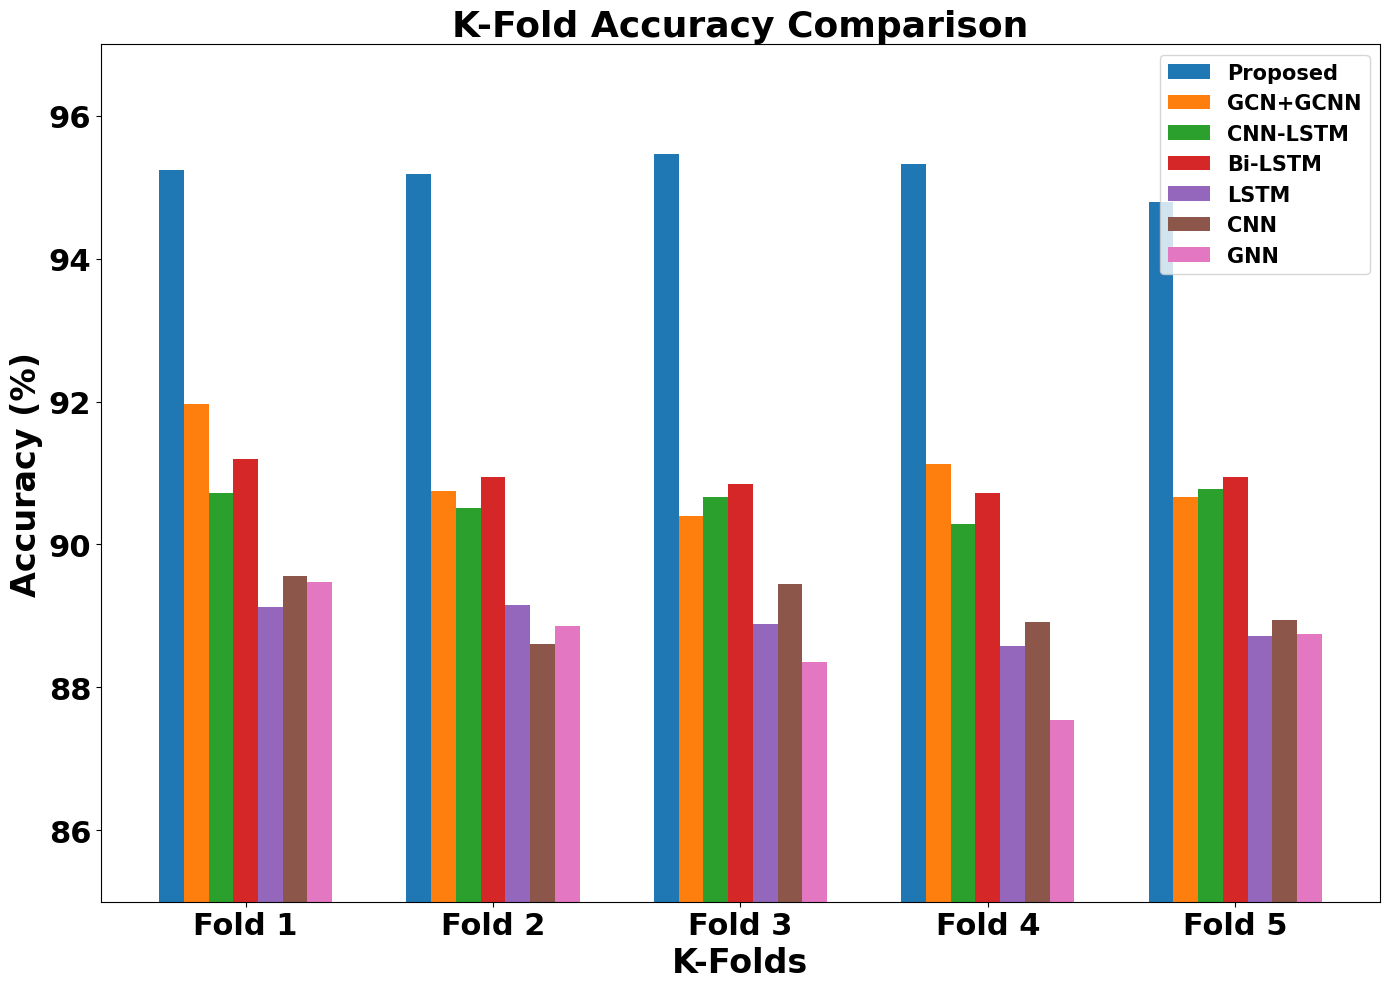

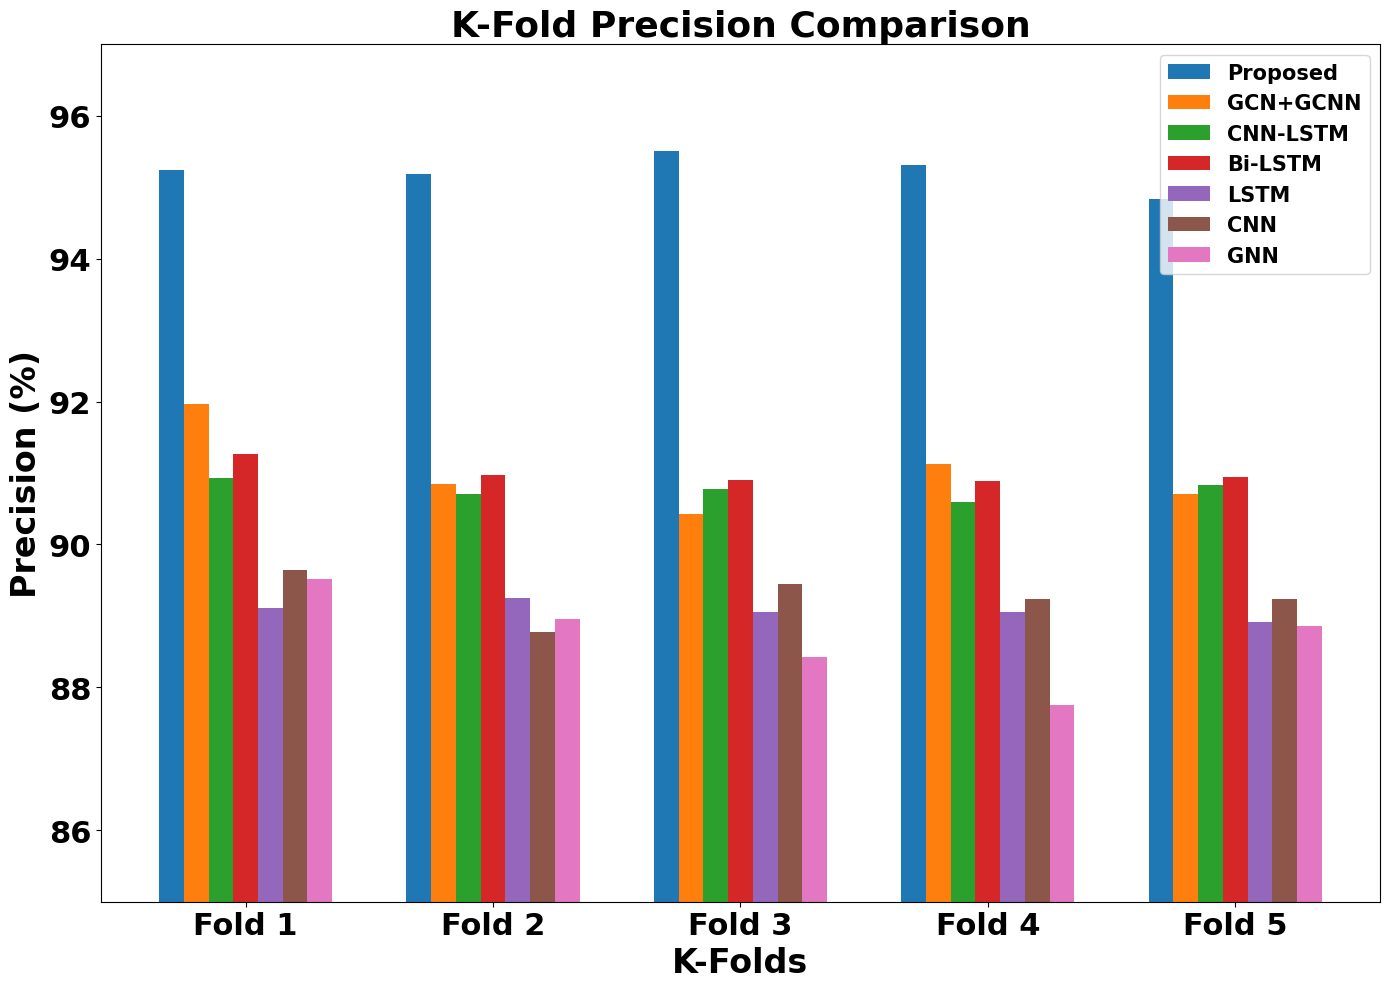

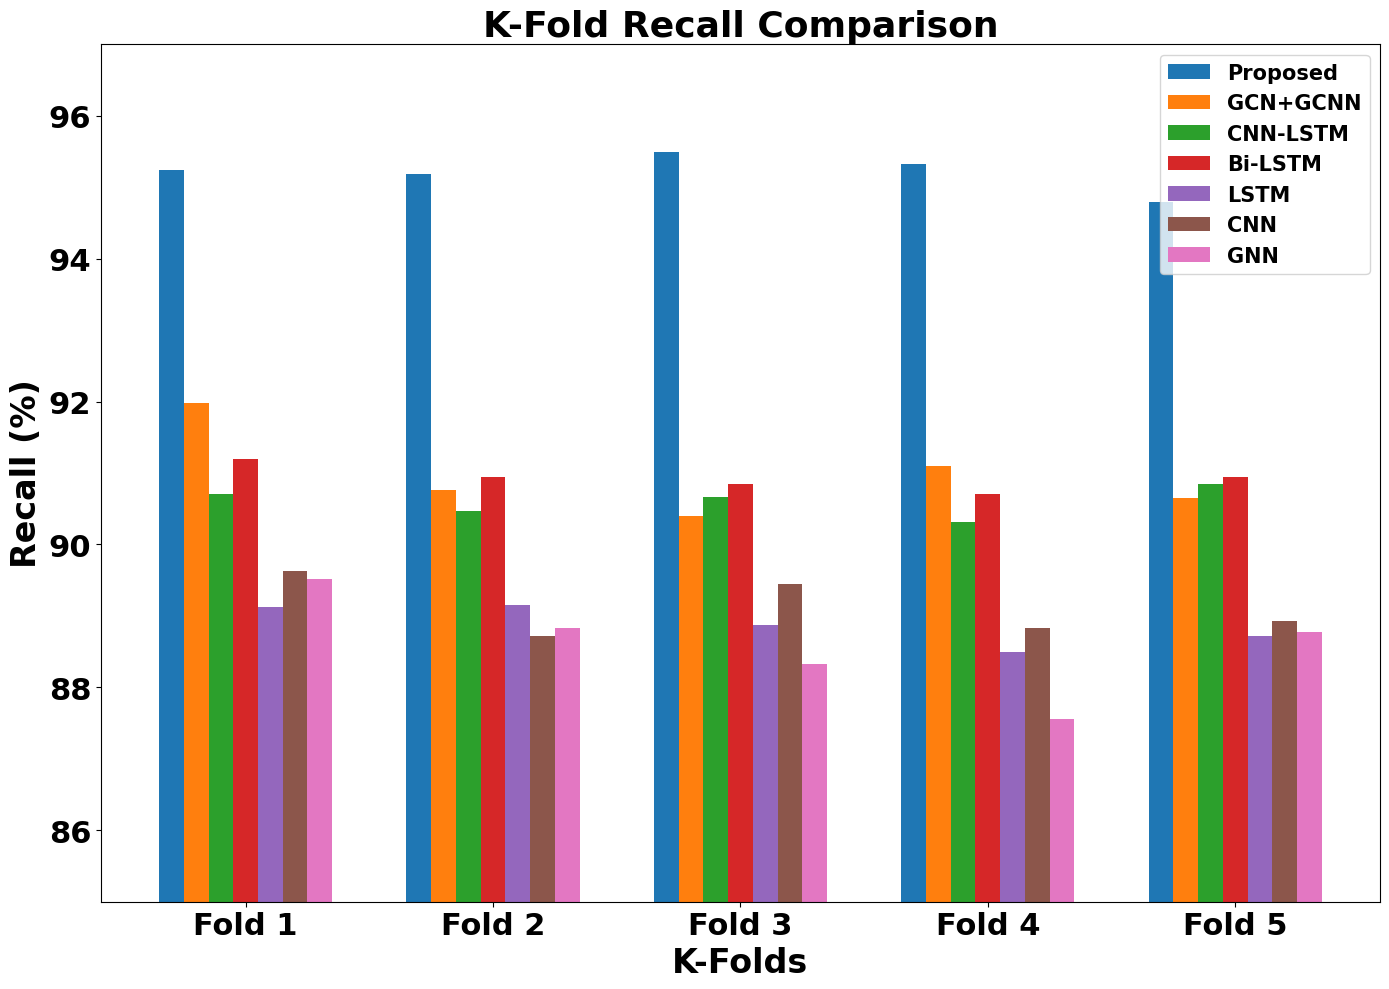

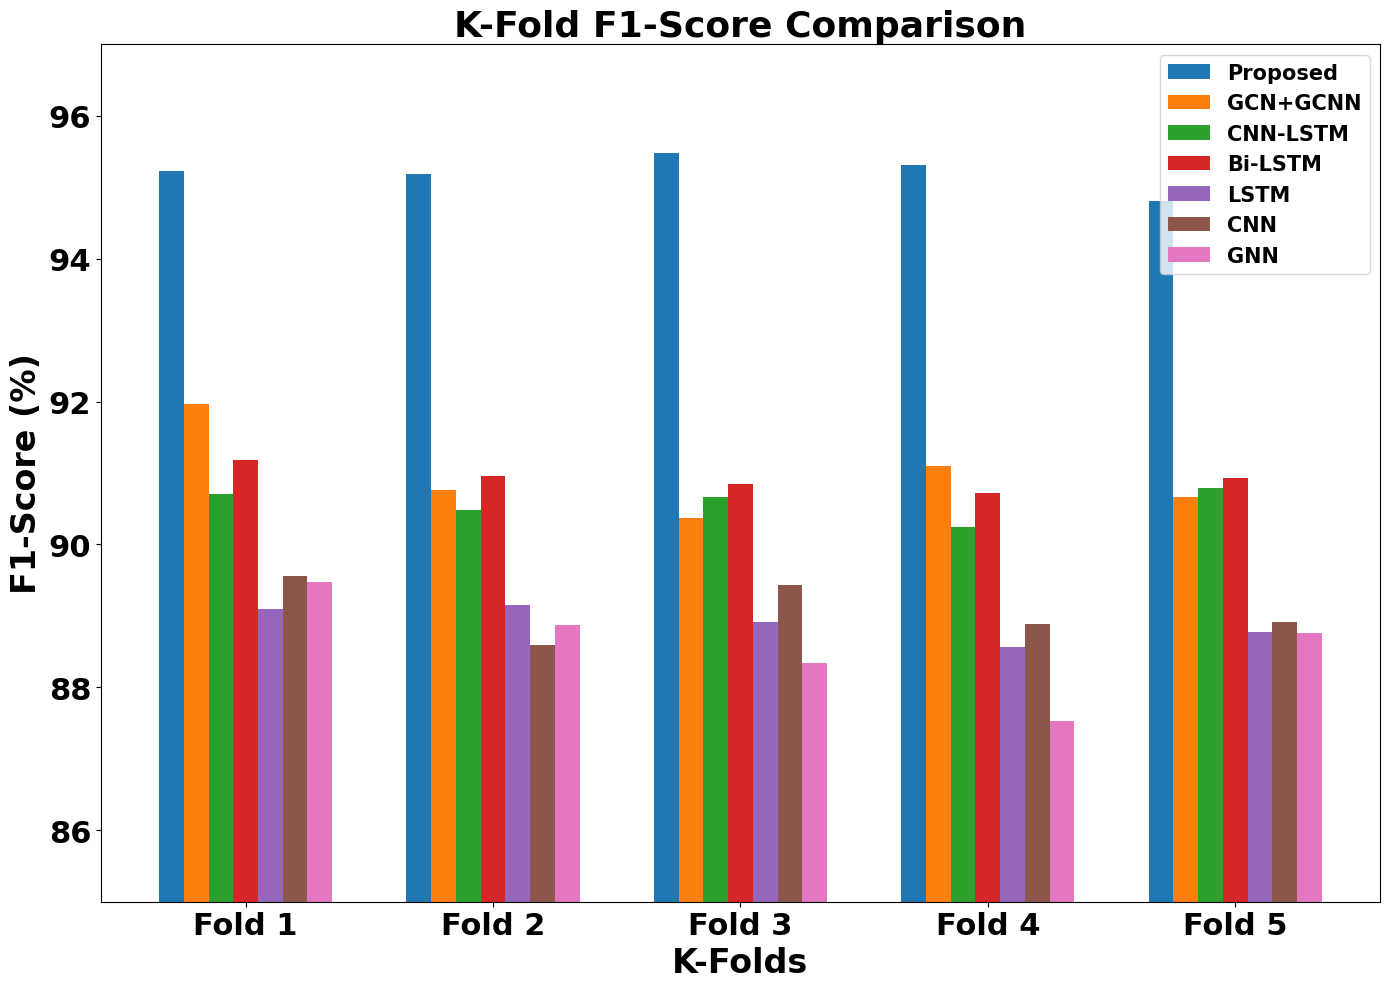

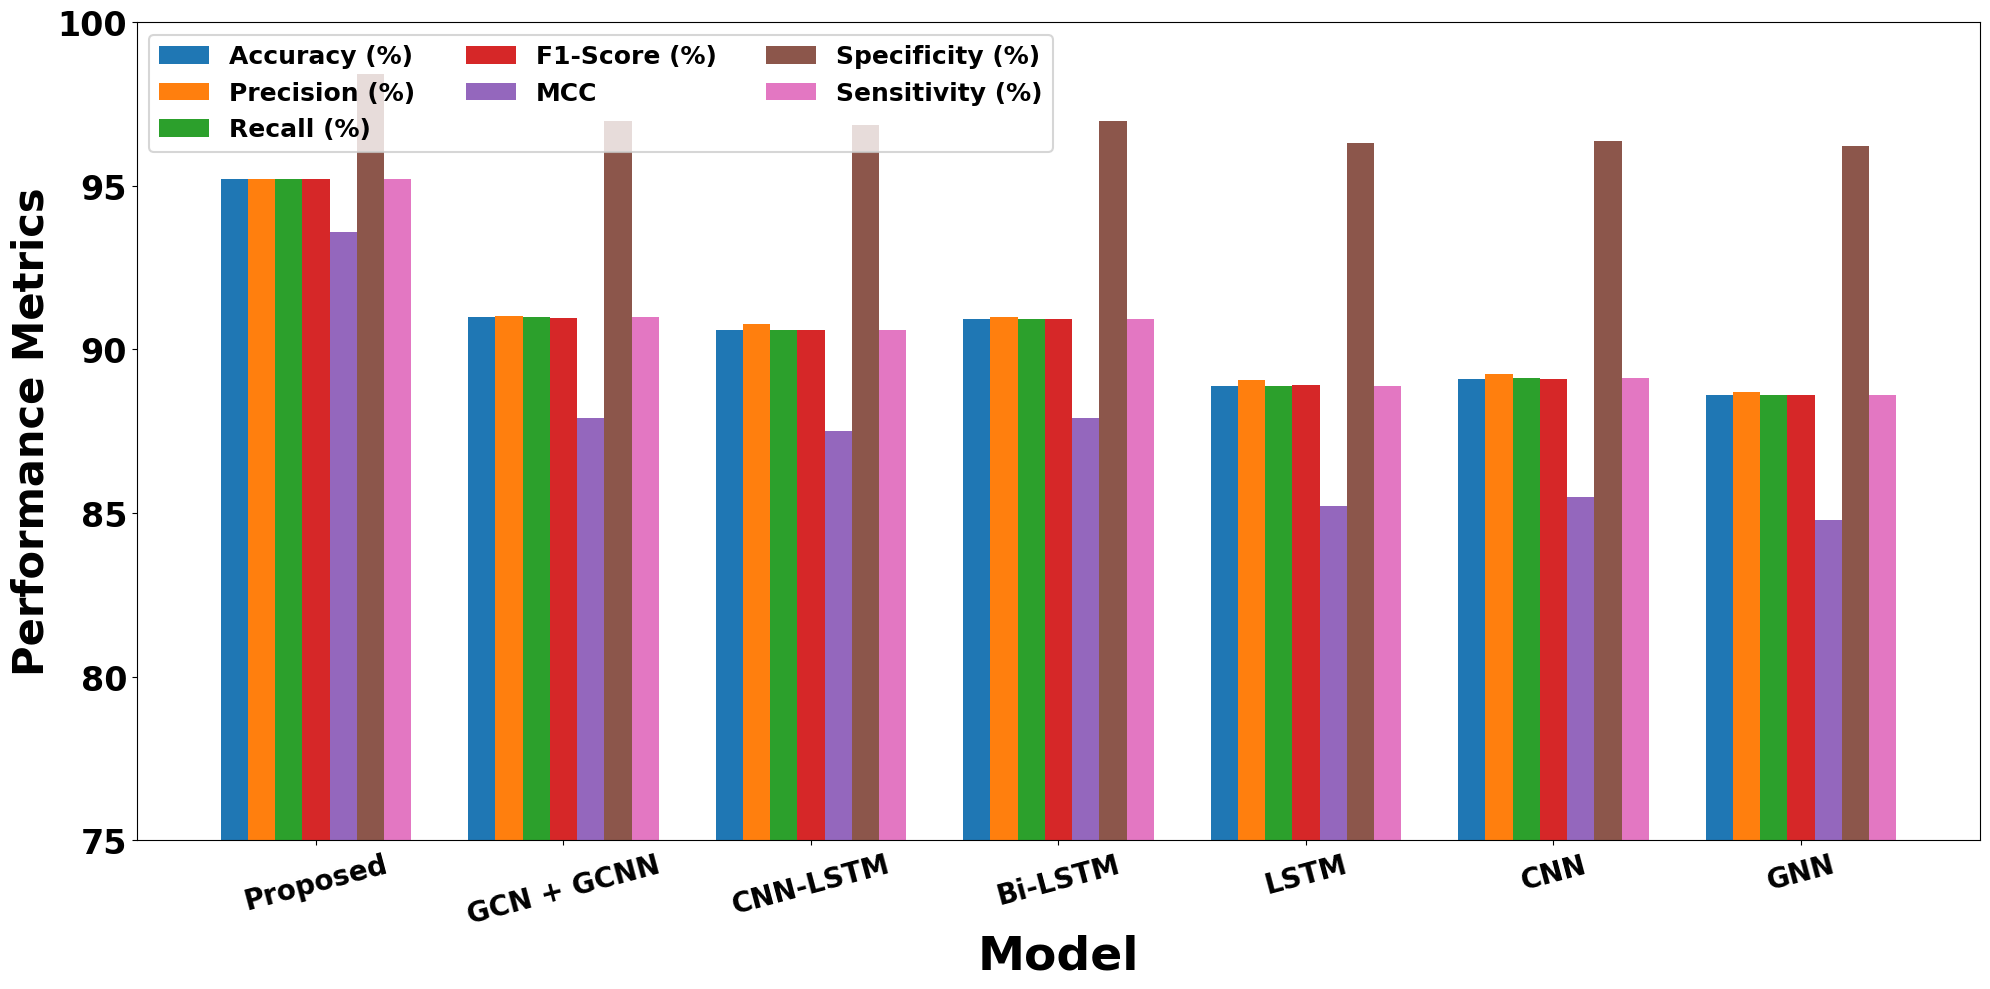

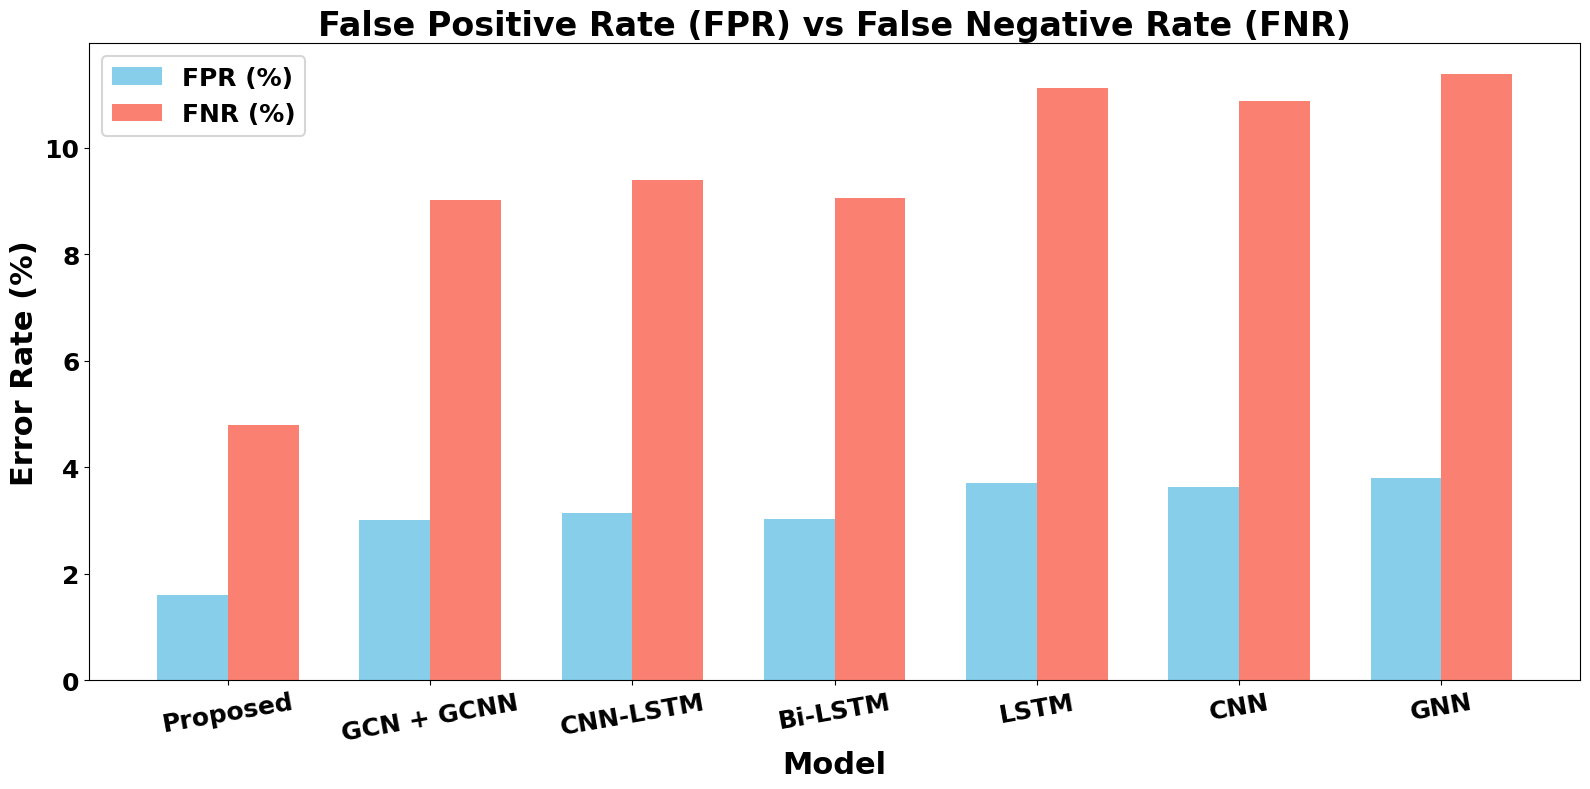

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# =========================
# Models and K-Folds
# =========================
models = ['Proposed', 'GCN+GCNN', 'CNN-LSTM', 'Bi-LSTM', 'LSTM', 'CNN', 'GNN']
kfolds = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']

# =========================
# DATA FROM YOUR TABLE
# =========================

accuracy = np.array([
    [95.24, 95.19, 95.46, 95.32, 94.79],
    [91.97, 90.75, 90.40, 91.12, 90.66],
    [90.72, 90.51, 90.66, 90.29, 90.78],
    [91.19, 90.95, 90.85, 90.72, 90.94],
    [89.12, 89.15, 88.89, 88.58, 88.72],
    [89.56, 88.61, 89.44, 88.91, 88.94],
    [89.48, 88.86, 88.36, 87.55, 88.75]
])

precision = np.array([
    [95.24, 95.19, 95.51, 95.31, 94.84],
    [91.97, 90.84, 90.42, 91.13, 90.70],
    [90.93, 90.70, 90.78, 90.59, 90.83],
    [91.26, 90.97, 90.90, 90.89, 90.94],
    [89.11, 89.25, 89.05, 89.05, 88.91],
    [89.64, 88.78, 89.45, 89.23, 89.23],
    [89.52, 88.96, 88.42, 87.75, 88.86]
])

recall = np.array([
    [95.24, 95.18, 95.49, 95.32, 94.80],
    [91.98, 90.76, 90.40, 91.10, 90.65],
    [90.70, 90.47, 90.67, 90.31, 90.84],
    [91.20, 90.95, 90.85, 90.70, 90.95],
    [89.12, 89.15, 88.87, 88.50, 88.72],
    [89.63, 88.72, 89.44, 88.83, 88.93],
    [89.51, 88.83, 88.33, 87.56, 88.78]
])

f1 = np.array([
    [95.23, 95.18, 95.48, 95.31, 94.81],
    [91.97, 90.76, 90.37, 91.10, 90.66],
    [90.71, 90.48, 90.67, 90.24, 90.79],
    [91.18, 90.96, 90.84, 90.72, 90.93],
    [89.09, 89.15, 88.92, 88.57, 88.77],
    [89.56, 88.60, 89.43, 88.88, 88.91],
    [89.48, 88.87, 88.34, 87.53, 88.76]
])

# =========================
# BAR SETTINGS
# =========================
x = np.arange(len(kfolds))
bar_width = 0.10

# =========================
# FUNCTION FOR PLOTTING
# =========================
def plot_metric(data, title, ylabel, ylim):
    plt.figure(figsize=(14, 10))

    for i in range(len(models)):
        plt.bar(x + i * bar_width, data[i],
                width=bar_width, label=models[i])

    plt.xlabel('K-Folds', fontsize=24, fontweight='bold')
    plt.ylabel(ylabel, fontsize=24, fontweight='bold')
    plt.title(title, fontsize=26, fontweight='bold')

    plt.xticks(x + bar_width*3, kfolds, fontsize=22, fontweight='bold')
    plt.yticks(fontsize=22, fontweight='bold')
    plt.ylim(ylim)

    legend = plt.legend(fontsize=15)
    for text in legend.get_texts():
        text.set_fontweight('bold')


    plt.tight_layout()
    plt.show()

# =========================
# PLOTS (4 GRAPHS)
# =========================

plot_metric(accuracy, "K-Fold Accuracy Comparison", "Accuracy (%)", (85, 97))
plot_metric(precision, "K-Fold Precision Comparison", "Precision (%)", (85, 97))
plot_metric(recall, "K-Fold Recall Comparison", "Recall (%)", (85, 97))
plot_metric(f1, "K-Fold F1-Score Comparison", "F1-Score (%)", (85, 97))
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Models
# =========================
models = [
    'Proposed',
    'GCN + GCNN',
    'CNN-LSTM',
    'Bi-LSTM',
    'LSTM',
    'CNN',
    'GNN'
]

# =========================
# Metrics
# =========================
accuracy = [95.2, 90.98, 90.59, 90.93, 88.89, 89.09, 88.6]
precision = [95.21, 91.01, 90.77, 90.99, 89.07, 89.26, 88.7]
recall = [95.2, 90.98, 90.6, 90.93, 88.87, 89.11, 88.6]
f1_score = [95.2, 90.97, 90.58, 90.92, 88.9, 89.08, 88.6]
mcc = [93.6, 87.9, 87.5, 87.9, 85.2, 85.5, 84.8]
specificity = [98.4, 96.99, 96.86, 96.97, 96.29, 96.36, 96.2]
sensitivity = [95.2, 90.98, 90.6, 90.93, 88.87, 89.11, 88.6]

metrics = [accuracy, precision, recall, f1_score, mcc, specificity, sensitivity]

metric_names = [
    'Accuracy (%)',
    'Precision (%)',
    'Recall (%)',
    'F1-Score (%)',
    'MCC',
    'Specificity (%)',
    'Sensitivity (%)'
]

# =========================
# Bar Plot
# =========================
x = np.arange(len(models))
width = 0.11

plt.figure(figsize=(20,10))

for i, metric in enumerate(metrics):
    plt.bar(x + i * width, metric, width, label=metric_names[i])

# =========================
# Formatting
# =========================
plt.xlabel('Model', fontsize=34, fontweight='bold')
plt.ylabel('Performance Metrics', fontsize=30, fontweight='bold')

plt.xticks(
    x + width * 3,
    models,
    fontsize=20,
    fontweight='bold',
    rotation=15
)

plt.yticks(fontsize=24, fontweight='bold')
plt.ylim(75, 100)

legend = plt.legend(fontsize=18, ncol=3, frameon=True)
for text in legend.get_texts():
    text.set_fontweight('bold')

legend.get_frame().set_linewidth(1.5)

plt.tight_layout()
plt.show()
import numpy as np
import matplotlib.pyplot as plt
# =========================
# Models
# =========================
models = [
    'Proposed',
    'GCN + GCNN',
    'CNN-LSTM',
    'Bi-LSTM',
    'LSTM',
    'CNN',
    'GNN'
]

# =========================
# Metrics (%)
# =========================
FPR = [1.59, 3.00, 3.13, 3.02, 3.70, 3.63, 3.80]
FNR = [4.79, 9.02, 9.40, 9.06, 11.12, 10.88, 11.39]

# =========================
# Bar Plot
# =========================
x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(16,8))

# Bar for FPR
plt.bar(x - width/2, FPR, width, label='FPR (%)', color='skyblue')

# Bar for FNR
plt.bar(x + width/2, FNR, width, label='FNR (%)', color='salmon')

# =========================
# Formatting
# =========================
plt.xlabel('Model', fontsize=22, fontweight='bold')
plt.ylabel('Error Rate (%)', fontsize=22, fontweight='bold')

plt.xticks(x, models, fontsize=18, fontweight='bold', rotation=10)
plt.yticks(fontsize=18, fontweight='bold')

plt.title('False Positive Rate (FPR) vs False Negative Rate (FNR)',
          fontsize=24, fontweight='bold')

# Legend
legend = plt.legend(fontsize=18, frameon=True)
for text in legend.get_texts():
    text.set_fontweight('bold')

legend.get_frame().set_linewidth(1.5)

plt.tight_layout()
plt.show()